# 06 — Presenting uncertainty

This notebook turns the h=24 champion's point forecast into prediction intervals, checks whether they deliver the coverage they claim (overall, per zone and per horizon), measures how much forecast weather adds, and picks the chart for each audience.

**Inputs:** `panel.parquet`, `best_params.json`, the per-horizon champions from `nb04`, regime labels from notebook 05, `weather_forecast_holdout.parquet`.
**Outputs:** ledger block `nb06`; `holdout_quantiles.parquet` and `data/processed/uncertainty/`; figures `06_ci_vs_pi`, `06_calibration`, `06_mondrian_by_zone`, `06_coverage_by_horizon`, `06_weather_uncertainty`, `06_operational_weather`, `06_fan_chart`, `06_overlap_vs_paired`.

### 6.1 — Quantile forecasts

Quantile gradient boosting at 0.05, 0.25, 0.5, 0.75, 0.95 on the champion's features. Reserve is a quantile question, so a squared-error model answers the wrong one. Independently fitted quantiles can cross; the cell measures the crossing rate and fixes it by sorting each row (monotone rearrangement), asserting that the summed pinball loss does not rise.

In [1]:
# WHAT: load the CHAMPION configuration notebook 04 tuned, and fit quantile models on it.
# WHY:  the scaffold fitted its own HistGradientBoosting with DEFAULT hyperparameters
#       on `R.require("nb01", "chosen_lags")` -- the h=1 lag set. At h=24 a lag of 1
#       is not observable, so those intervals would have come from a model that was
#       neither tuned nor admissible. Uncertainty is a property OF A MODEL; quoting
#       intervals from a different model than the one whose point forecast ships is
#       not a presentation choice, it is a different result.
# NOTE: the notebook 04 ladder scored the quantile GBM (median) within ~64 MW of the
#       untuned squared-error HGB on the identical feature set (CV 2,237.5 against
#       2,173.6 MW), which is what licenses reusing that
#       feature set here rather than re-searching for the quantile loss.
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

from src import config as cfg
from src import results as R
from src import features as P
from src import models as X
from src import uncertainty as U

pd.set_option("display.width", 140, "display.max_columns", 50)
plt.rcParams["figure.figsize"] = cfg.FIGSIZE
plt.rcParams["figure.dpi"] = cfg.DPI
np.random.seed(cfg.SEED)

HORIZON = R.get("nb04", "horizon_primary", default=24)
BP = json.loads((cfg.DATA_PROC / "best_params.json").read_text(encoding="utf-8"))
PARAMS = BP["params"]
# Notebook 04 §4.6b now tunes a champion PER HORIZON. This notebook reports intervals at the
# primary horizon, so it takes that horizon's configuration rather than a file that
# happens to hold whichever search ran last.
_per_h = R.get("nb04", "per_horizon_champions", default=None)
if _per_h and str(HORIZON) in _per_h:
    PARAMS = _per_h[str(HORIZON)]["params"]
    print(f"using the h={HORIZON} champion from notebook 04 §4.6b")
LAGS = tuple(PARAMS["lag__lags"])
ROLLS = tuple(PARAMS["lag__roll_windows"])
SEL_K = PARAMS["select__k"]
MODEL_PARAMS = {k.split("__", 1)[1]: v for k, v in PARAMS.items()
                if k.startswith("model__")}

print(f"champion from notebook 04 (h={BP['horizon']}, CV MAE {BP['cv_mae']:,.1f} MW)")
for k, v in sorted(PARAMS.items()):
    print(f"   {k:26s} {v}")

_df, dev, hold, cut = X.analysis_frames(HORIZON)
y_dev, y_hold = dev[cfg.TARGET].to_numpy(), hold[cfg.TARGET].to_numpy()
print(f"\ndev {len(dev):,} rows to {cut:%Y-%m-%d}   holdout {len(hold):,} rows")


def quantile_pipe(q, noise_scale=None, lags=LAGS, rolls=ROLLS):
    """The champion pipeline with the quantile loss substituted for squared error."""
    return P.make_supervised_pipeline(
        cfg.NUMERIC_FEATURES, lags=lags, roll_windows=rolls, k=SEL_K,
        weather_noise_scale=noise_scale,
        model=HistGradientBoostingRegressor(
            loss="quantile", quantile=q, random_state=cfg.SEED, **MODEL_PARAMS))


QS = [0.05, 0.25, 0.5, 0.75, 0.95]
Q = pd.DataFrame(index=range(len(hold)))
for q in QS:
    Q[q] = quantile_pipe(q).fit(dev, y_dev).predict(hold)
    print(f"   fitted q={q:.2f}")

# QUANTILE CROSSING is a real failure mode, not a formality: five models fitted
# independently have no constraint tying them together, so a 25th percentile can
# come out above a 75th. Measured before anything is built on top of them.
cross_rate = U.crossing_rate(Q, QS)
print(f"\nquantile crossing on {cross_rate:.3%} of holdout rows BEFORE rearrangement")

# ---------------------------------------------------------------------------
# FIX 1 of 3 — MONOTONE REARRANGEMENT (Chernozhukov, Fernandez-Val, Galichon 2010)
# ---------------------------------------------------------------------------
# Sort each row's quantile predictions. The argument that makes this FREE rather
# than a trade: a predicted quantile curve that decreases somewhere is not a
# distribution function, so it cannot be right, and the monotone projection of a
# curve is weakly closer to any monotone target in every L^p norm. On the data,
# sorting can only LOWER the pinball loss summed over the levels (swapping a crossed
# pair lowers it row by row); no single level is guaranteed to improve. The summed
# version is asserted below and in tests/test_uncertainty.py, and the crossing rate
# goes to exactly zero.
#
# WHAT IT DOES NOT FIX, said here because it is the easiest wrong claim to make:
# rearrangement is a statement about ORDER, not LEVEL. A band that is uniformly too
# narrow is still too narrow afterwards. Coverage is fix 2.
Q_raw = Q.copy()
Q = U.rearrange(Q, QS)
cross_after = U.crossing_rate(Q, QS)
pin_before = {q: U.pinball(y_hold, Q_raw[q], q) for q in QS}
pin_after = {q: U.pinball(y_hold, Q[q], q) for q in QS}
print(f"quantile crossing on {cross_after:.3%} of holdout rows AFTER rearrangement")
print(f"mean pinball loss  {np.mean(list(pin_before.values())):,.2f} -> "
      f"{np.mean(list(pin_after.values())):,.2f} MW  "
      f"(the theorem says this cannot go up)")
for q in QS:
    print(f"   q={q:.2f}  pinball {pin_before[q]:9,.2f} -> {pin_after[q]:9,.2f}  "
          f"{pin_after[q] - pin_before[q]:+7,.2f}")
assert sum(pin_after.values()) <= sum(pin_before.values()) + 1e-6, \
    "rearrangement made the pinball loss worse, which the theorem forbids"


using the h=24 champion from notebook 04 §4.6b
champion from notebook 04 (h=24, CV MAE 2,107.3 MW)
   lag__lags                  [24, 25, 26, 48, 168]
   lag__roll_windows          [24]
   model__l2_regularization   0.0
   model__learning_rate       0.04
   model__max_depth           8
   model__max_iter            1200
   model__min_samples_leaf    100
   select__k                  all

dev 268,186 rows to 2024-02-06   holdout 47,299 rows


   fitted q=0.05


   fitted q=0.25


   fitted q=0.50


   fitted q=0.75


   fitted q=0.95

quantile crossing on 10.034% of holdout rows BEFORE rearrangement
quantile crossing on 0.000% of holdout rows AFTER rearrangement
mean pinball loss  680.40 -> 678.78 MW  (the theorem says this cannot go up)
   q=0.05  pinball    321.01 ->    319.13    -1.87
   q=0.25  pinball    863.98 ->    863.02    -0.96
   q=0.50  pinball  1,074.42 ->  1,071.64    -2.78
   q=0.75  pinball    854.76 ->    853.02    -1.74
   q=0.95  pinball    287.82 ->    287.11    -0.71


### 6.1b — Confidence interval vs prediction interval

On the holdout residuals of the median forecast: the 90% confidence interval for the *mean* error and the 90% prediction interval for the *next* error. The mean error is known more precisely with more data (epistemic); the next hour's error is not (aleatoric). Reserve is held against the next hour, so it is sized from the prediction interval. The empirical band is shipped and a Gaussian band is drawn beside it, because forecast errors have heavy tails.

holdout median-forecast error, n = 47,299
   90% CONFIDENCE interval for the MEAN error  [   -311.0,    -260.6] MW   half-width     25.2
   90% PREDICTION interval, empirical          [ -5,893.5,  +5,000.2] MW   half-width  5,446.8
   90% PREDICTION interval, Gaussian           [ -5,763.3,  +5,191.8] MW   half-width  5,477.6
   ratio of half-widths, PI / CI  216x   (sqrt(n) = 217)
   90% CI for the mean error on 1,974 zone-day blocks  [   -375.1,    -191.8] MW   half-width     91.7; PI / CI 59x
   achieved coverage on the holdout: empirical PI 90.0%, Gaussian PI 90.1%
   reserve read off the PI upper edge 5,000 MW; off the CI upper edge -261 MW

--- by zone: the ratio is a property of n and the spread, and both differ ---


,n,ci_half_width,pi_half_width,pi_gaussian_half_width,ratio_pi_to_ci,sqrt_n
CISO,7872.0,34.9,3041.2,3100.5,87.0,88.7
ERCO,7896.0,88.4,7831.1,7849.9,88.6,88.9
MISO,7872.0,92.6,6978.2,8212.0,75.4,88.7
SWPP,7872.0,69.0,5972.9,6120.5,86.6,88.7
BPAT,7891.0,11.7,1020.6,1040.0,87.2,88.8
NYIS,7896.0,15.3,1329.1,1357.1,87.0,88.9


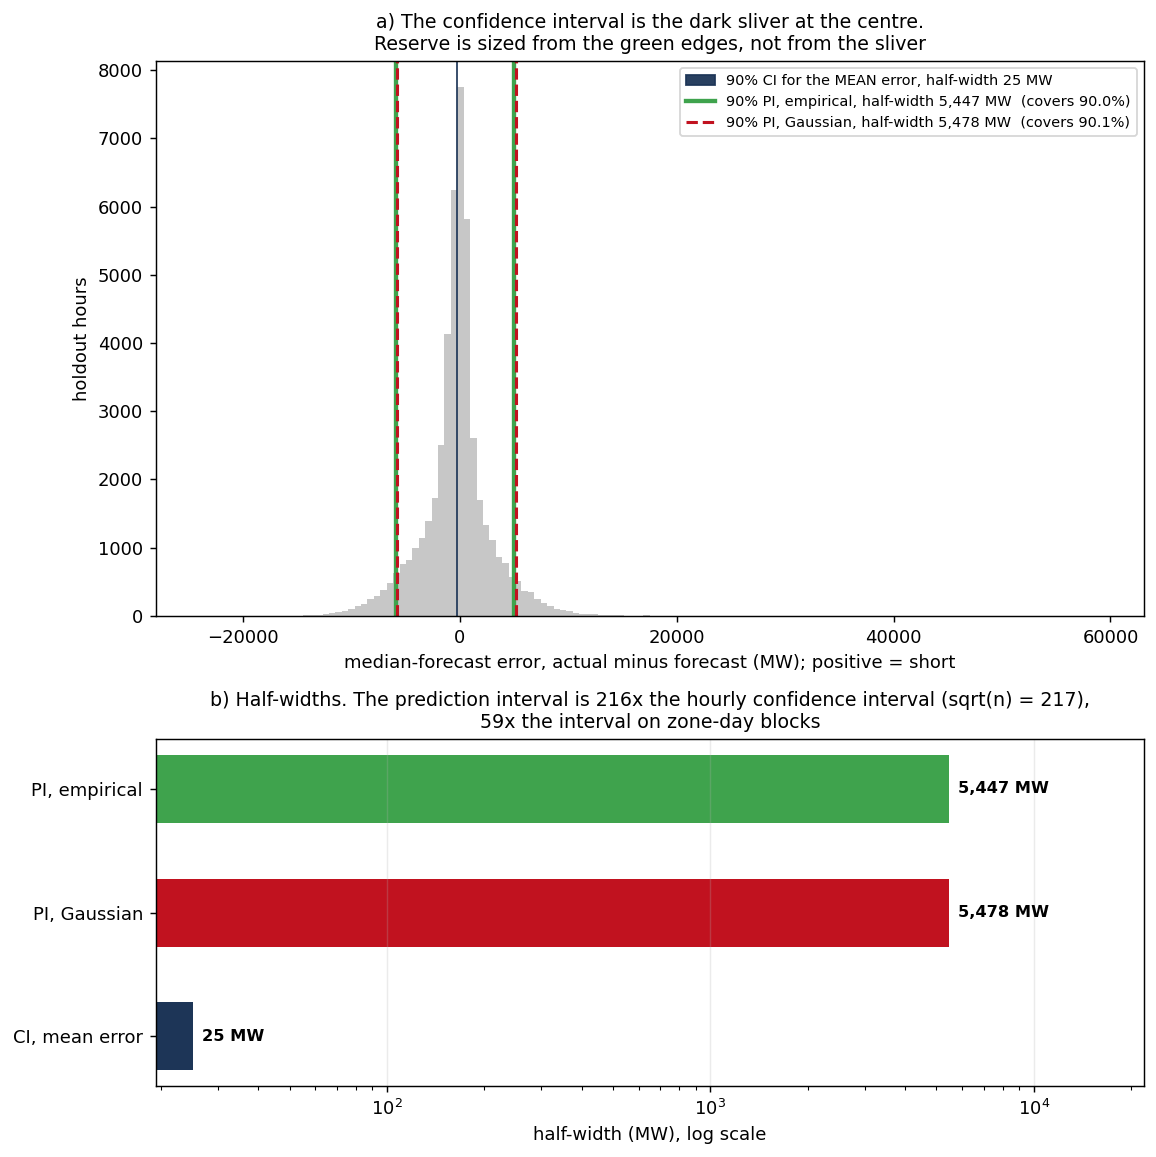

In [2]:
# WHAT: the confidence interval for the MEAN error and the prediction interval for
#       the NEXT error, on the same holdout residuals of the median forecast.
# WHY:  reserve is bought against the next hour, not the average hour. Sizing it
#       from the confidence interval understates it by roughly sqrt(n); the plan
#       asks for that factor from this data rather than from a textbook.
# TRADE-OFF: the empirical quantile band is shipped over the Gaussian one. Gaussian
#       needs one parameter and is smooth; it also assumes a tail shape the errors
#       do not have, and reserve is spent in the tail. Both are drawn.
e_med = y_hold - Q[0.5].to_numpy()      # positive = under-forecast = the system is short
zone_hold = hold[cfg.GROUP_COL].to_numpy()
cp = U.ci_vs_pi(e_med, 0.90)
print(f"holdout median-forecast error, n = {cp['n']:,}")
print(f"   90% CONFIDENCE interval for the MEAN error  [{cp['ci'][0]:+9,.1f}, {cp['ci'][1]:+9,.1f}] MW"
      f"   half-width {cp['ci_half_width']:8,.1f}")
print(f"   90% PREDICTION interval, empirical          [{cp['pi'][0]:+9,.1f}, {cp['pi'][1]:+9,.1f}] MW"
      f"   half-width {cp['pi_half_width']:8,.1f}")
print(f"   90% PREDICTION interval, Gaussian           [{cp['pi_gaussian'][0]:+9,.1f}, "
      f"{cp['pi_gaussian'][1]:+9,.1f}] MW   half-width {cp['pi_gaussian_half_width']:8,.1f}")
print(f"   ratio of half-widths, PI / CI  {cp['ratio_pi_to_ci']:,.0f}x   (sqrt(n) = {cp['sqrt_n']:,.0f})")
# THE CI ABOVE TREATS 47,000 AUTOCORRELATED HOURS AS INDEPENDENT; it is the textbook
# interval the sqrt(n) argument is about. The honest interval for the mean error is
# computed on zone-day block means, the unit of independence used for every paired test.
_blk_id = (pd.Series(zone_hold, dtype=str) + "|"
           + hold[cfg.TIME_COL].dt.date.astype(str).reset_index(drop=True)).to_numpy()
_blk = pd.Series(e_med).groupby(_blk_id).mean().to_numpy()
ci_blk = U.confidence_interval(_blk, 0.90)
hw_blk = (ci_blk[1] - ci_blk[0]) / 2
print(f"   90% CI for the mean error on {len(_blk):,} zone-day blocks  [{ci_blk[0]:+9,.1f}, "
      f"{ci_blk[1]:+9,.1f}] MW   half-width {hw_blk:8,.1f}; PI / CI {cp['pi_half_width'] / hw_blk:,.0f}x")
_full = lambda v: np.full(len(e_med), v)
cov_pi = U.coverage(e_med, _full(cp["pi"][0]), _full(cp["pi"][1]))
cov_pg = U.coverage(e_med, _full(cp["pi_gaussian"][0]), _full(cp["pi_gaussian"][1]))
print(f"   achieved coverage on the holdout: empirical PI {cov_pi:.1%}, Gaussian PI {cov_pg:.1%}")
# Reserve is the UPPER edge: how short the system can be at the 95th percentile.
reserve_pi, reserve_ci = cp["pi"][1], cp["ci"][1]
print(f"   reserve read off the PI upper edge {reserve_pi:,.0f} MW; off the CI upper edge "
      f"{reserve_ci:,.0f} MW")

cp_zone = pd.DataFrame({z: U.ci_vs_pi(e_med[zone_hold == z], 0.90) for z in cfg.ZONES}).T[
    ["n", "ci_half_width", "pi_half_width", "pi_gaussian_half_width", "ratio_pi_to_ci", "sqrt_n"]
].astype(float)
print("\n--- by zone: the ratio is a property of n and the spread, and both differ ---")
display(cp_zone.round(1))

fig, axes = plt.subplots(2, 1, figsize=(9.0, 9.0), gridspec_kw={"height_ratios": [1.6, 1]})
ax = axes[0]
ax.hist(e_med, bins=140, color="0.78", edgecolor="none")
ax.axvspan(cp["ci"][0], cp["ci"][1], color="#1d3557", alpha=0.95,
           label=f"90% CI for the MEAN error, half-width {cp['ci_half_width']:,.0f} MW")
ax.axvline(cp["pi"][0], color="#3fa34d", lw=2.4)
ax.axvline(cp["pi"][1], color="#3fa34d", lw=2.4,
           label=f"90% PI, empirical, half-width {cp['pi_half_width']:,.0f} MW  (covers {cov_pi:.1%})")
ax.axvline(cp["pi_gaussian"][0], color="#c1121f", lw=1.7, ls="--")
ax.axvline(cp["pi_gaussian"][1], color="#c1121f", lw=1.7, ls="--",
           label=f"90% PI, Gaussian, half-width {cp['pi_gaussian_half_width']:,.0f} MW  (covers {cov_pg:.1%})")
ax.set_xlabel("median-forecast error, actual minus forecast (MW); positive = short")
ax.set_ylabel("holdout hours")
ax.set_title("a) The confidence interval is the dark sliver at the centre.\n"
             "Reserve is sized from the green edges, not from the sliver", fontsize=10.5)
ax.legend(fontsize=8, loc="upper right")
ax = axes[1]
labels = ["CI, mean error", "PI, Gaussian", "PI, empirical"]
vals = [cp["ci_half_width"], cp["pi_gaussian_half_width"], cp["pi_half_width"]]
bars = ax.barh(labels, vals, color=["#1d3557", "#c1121f", "#3fa34d"], height=0.55)
ax.set_xscale("log")
for b_, v in zip(bars, vals):
    ax.annotate(f"{v:,.0f} MW", (v, b_.get_y() + b_.get_height() / 2), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(right=max(vals) * 4)
ax.set_xlabel("half-width (MW), log scale")
ax.set_title(f"b) Half-widths. The prediction interval is {cp['ratio_pi_to_ci']:,.0f}x the "
             f"hourly confidence interval (sqrt(n) = {cp['sqrt_n']:,.0f}),\n"
             f"{cp['pi_half_width'] / hw_blk:,.0f}x the interval on zone-day blocks", fontsize=10.5)
ax.grid(alpha=0.25, axis="x")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "06_ci_vs_pi.png", bbox_inches="tight")
plt.show()

R.save("nb06", {"ci_vs_pi": {
    "n": int(cp["n"]),
    "ci_mean_error_mw": [float(v) for v in cp["ci"]],
    "pi_90_mw": [float(v) for v in cp["pi"]],
    "pi_90_gaussian_mw": [float(v) for v in cp["pi_gaussian"]],
    "ci_half_width_mw": float(cp["ci_half_width"]),
    "pi_half_width_mw": float(cp["pi_half_width"]),
    "pi_gaussian_half_width_mw": float(cp["pi_gaussian_half_width"]),
    "ratio_pi_to_ci": float(cp["ratio_pi_to_ci"]),
    "ci_mean_error_blocked_mw": [float(v) for v in ci_blk],
    "ci_blocked_half_width_mw": float(hw_blk),
    "n_blocks": int(len(_blk)),
    "ratio_pi_to_ci_blocked": float(cp["pi_half_width"] / hw_blk),
    "sqrt_n": float(cp["sqrt_n"]),
    "coverage_pi_empirical": float(cov_pi),
    "coverage_pi_gaussian": float(cov_pg),
    "reserve_from_pi_upper_mw": float(reserve_pi),
    "reserve_from_ci_upper_mw": float(reserve_ci),
    "by_zone": {z: {k: float(v) for k, v in cp_zone.loc[z].items()} for z in cp_zone.index},
}});


**Figure: `06_ci_vs_pi.png`**

**What this shows:** The histogram of the 47,299 holdout residuals, with the 90% CI for the mean error (dark sliver) and the 90% prediction interval, empirical and Gaussian; panel (b) compares the half-widths.

**What I see:** The CI is [−311, −261] MW, half-width 25 MW. The empirical PI is [−5,894, +5,000] MW (half-width 5,447 MW, coverage 90.0%); the Gaussian PI has half-width 5,478 MW and covers 90.1%. The ratio is 216×, close to √n = 217, but hours are autocorrelated: on 1,974 zone-day blocks the CI is [−375, −192] MW (half-width 92 MW) and the ratio is 59×.

**What it means:** The mean error is negative: the median forecast runs about 286 MW high on average. Sizing reserve from the CI would say no reserve is needed (upper edge −261 MW); the PI's upper edge is 5,000 MW. At 90% the Gaussian and empirical bands agree, so the heavy tail only matters further out.

**What I do:** Ship the empirical PI, quote the factor as 59× (zone-day blocks), and never show a CI in an operational context.

### 6.2 — Calibration: three defects and their fixes

The raw 90% band covers only 80.4%, the median sits at 0.541 instead of 0.500, and the quantiles cross on 10.0% of rows. Fixes, all learned on a chronological calibration block (the last 20% of dev):

1. **Crossings:** monotone rearrangement (sort each row).
2. **Coverage:** conformalized quantile regression (CQR), one margin added to both edges; additive and scaled versions are scored.
3. **Median:** a one-sided conformal shift per quantile level.
4. **Mondrian by zone:** fixes 2 and 3 refitted within each zone, so coverage is promised per balancing authority. Zone is used, not regime, because the regime of a day is not known at forecast time.

The shipped arm is CQR additive, Mondrian by zone, chosen by rule before the run. Nine arms are compared, including a raw model on the smaller fit block so the effect of the correction is not confused with the loss of training rows. Coverage is also reported by regime and for duck evenings (regime 2, local 16:00–21:00). The calibrated models forecast the holdout with their lag buffer rebuilt from the whole dev period (`P.with_history`).

calibration split: fit on 214,552 rows to 2023-01-30, calibrate on 53,634 rows after it


   fitted q=0.05 on the fit block


   fitted q=0.10 on the fit block


   fitted q=0.25 on the fit block


   fitted q=0.50 on the fit block


...

,group,rows,coverage,mean_width,thin
0,0 winter-shaped,7395,0.9080,7305.8,False
1,1 conventional,25063,0.9001,8932.7,False
2,2 DUCK,14434,0.8555,8969.7,False
3,unlabelled,407,0.7690,11240.7,False



DUCK EVENINGS (regime 2, local 16:00-21:00, 3,612 rows): coverage 84.7%, mean width 9,982 MW
   against 88.7% marginal — the marginal number HIDES this cell

--- CQR additive, Mondrian by zone: coverage by zone ---


,group,rows,coverage,mean_width,thin
0,BPAT,7891,0.9167,2207.0,False
1,CISO,7872,0.8670,5743.5,False
2,ERCO,7896,0.8750,15266.6,False
3,MISO,7872,0.8810,14178.2,False
4,NYIS,7896,0.8889,2843.6,False
5,SWPP,7872,0.8910,12031.7,False


zone spread: pooled 19.6 pts -> Mondrian 5.0 pts; worst zone +3.3 pts from nominal, gate is 5.0

--- P(y <= median forecast) by zone; 0.500 is the promise ---


,raw,before shift,pooled shift,Mondrian shift
group,,,,
BPAT,0.472,0.437,0.429,0.502
CISO,0.605,0.604,0.600,0.609
ERCO,0.534,0.545,0.544,0.524
MISO,0.509,0.508,0.506,0.516
NYIS,0.553,0.566,0.558,0.558
SWPP,0.574,0.603,0.601,0.522


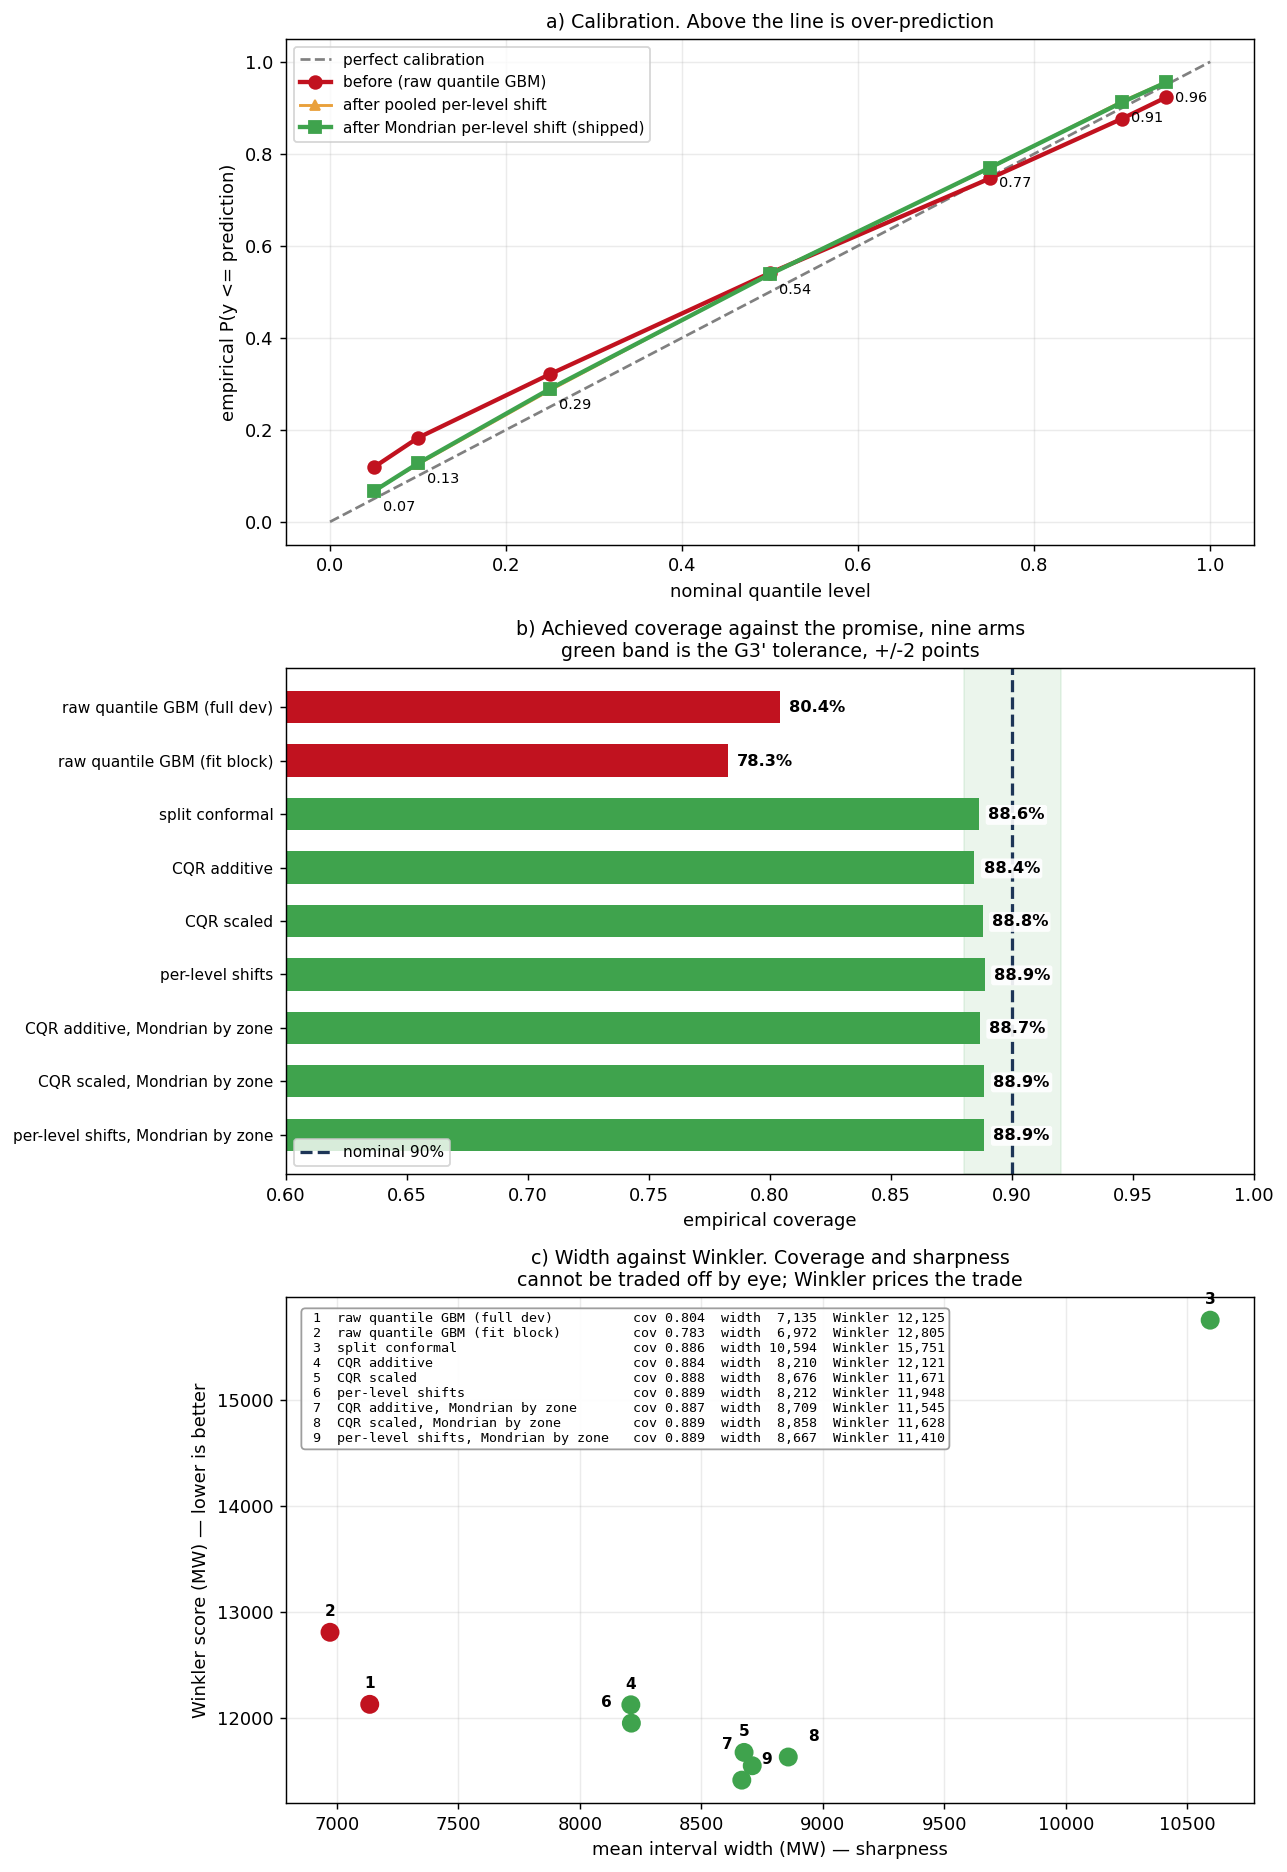

In [3]:
# WHAT: the three defects G3 failed on, each with a named fix, scored side by side.
# WHY:  notebook 06 previously reported 81.1% coverage at a nominal 90%, a median at
#       0.540 and crossings on 8.5% of rows, and reserve is sized off that
#       distribution. An interval 8.9 points too narrow does not merely read badly;
#       it under-prices the money number. This is where that is repaired.
#
# THE ARMS -- nine in the table: the four below, the pooled per-level shifts, and the
# Mondrian-by-zone versions of CQR additive, CQR scaled and the per-level shifts.
# Why each of the four is here rather than only the winner:
#   raw (full dev)     what has been reported until now. The reference point.
#   raw (fit block)    the SAME method on the smaller training block CQR needs.
#                      Without it, raw-versus-CQR would confound the correction with
#                      the 20% of training rows the correction costs.
#   split conformal    constant half-width on absolute residuals. Already in this
#                      notebook; kept because it is the obvious alternative and it
#                      loses on Winkler, which is the interesting part.
#   CQR                Romano, Patterson and Candes (2019), in both the additive and
#                      the scaled form. Additive carries the classic guarantee;
#                      scaled preserves the band's shape exactly.
from math import ceil
from src import uncertainty as U

yh = y_hold
ALPHA = 0.10
LEVELS = [0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]

# ---------------------------------------------------------------------------
# The calibration block — chronological, never random
# ---------------------------------------------------------------------------
# The conformal guarantee needs the calibration scores to be exchangeable with the
# test scores. They are not, strictly: this is a time series with drift and the
# holdout comes after everything. A RANDOM split would break it further by letting
# the calibration quantile see hours after the ones it calibrates, and would report
# a coverage no operating desk could reproduce. The last 20% of dev is the closest
# block in time to the holdout and is the honest choice.
CAL_FRAC = 0.20
sub_fit, sub_cal, cal_cut = U.chronological_calibration_split(dev, CAL_FRAC)
y_fit, y_cal = sub_fit[cfg.TARGET].to_numpy(), sub_cal[cfg.TARGET].to_numpy()
print(f"calibration split: fit on {len(sub_fit):,} rows to {cal_cut:%Y-%m-%d}, "
      f"calibrate on {len(sub_cal):,} rows after it")

# The SAME models produce the calibration-block and holdout predictions. Refitting
# between the two would calibrate one model and correct another.
Qc, Qt = {}, {}
for q in LEVELS:
    pipe_q = quantile_pipe(q).fit(sub_fit, y_fit)
    Qc[q] = pipe_q.predict(sub_cal)
    # The fit block ends a year before the holdout starts, so its own lag buffer cannot
    # reach the holdout's first week; at forecast time that week's lags are simply the
    # recent past, so the buffer is rebuilt from the whole dev block. Only the buffer
    # changes -- the model calibrated on the calibration block is the model applied here.
    Qt[q] = P.with_history(pipe_q, dev).predict(hold)
    print(f"   fitted q={q:.2f} on the fit block")
Qc = U.rearrange(pd.DataFrame(Qc), LEVELS)
Qt = U.rearrange(pd.DataFrame(Qt), LEVELS)

# ---------------------------------------------------------------------------
# FIX 2 — conformalized quantile regression
# ---------------------------------------------------------------------------
m_add = U.cqr_margin(y_cal, Qc[0.05], Qc[0.95], alpha=ALPHA)
m_scl = U.cqr_margin_scaled(y_cal, Qc[0.05], Qc[0.95], alpha=ALPHA)
cqr_lo, cqr_hi = U.apply_cqr(Qt[0.05], Qt[0.95], m_add)
cqrs_lo, cqrs_hi = U.apply_cqr_scaled(Qt[0.05], Qt[0.95], m_scl)
print(f"\nCQR additive margin {m_add:+,.1f} MW per side "
      f"({'widening' if m_add > 0 else 'NARROWING — the band was too wide'})")
print(f"CQR scaled  margin {m_scl:+.4f} x each row's own width")

# ---------------------------------------------------------------------------
# FIX 3 — the median, and every other level, by a one-sided conformal shift
# ---------------------------------------------------------------------------
Q_cal_levels, shifts = U.calibrate_levels(y_cal, Qc, Qt)
print(f"\nper-level conformal shifts (MW): "
      f"{ {float(k): round(v, 1) for k, v in shifts.items()} }")

# ---------------------------------------------------------------------------
# FIX 4 — MONDRIAN: the same corrections, fitted WITHIN EACH ZONE
# ---------------------------------------------------------------------------
# Pooled CQR is calibrated on average and wrong per balancing authority (BPAT
# 99.25%, ERCO 80.24% on 08-29), and the median bias flips sign between zones, so
# no scalar shift can remove it. Every correction below is refitted on each zone's
# own calibration rows. Zone, not regime: zone is known at forecast time, the
# regime label is not. The fit count does not change — this is a different way of
# reading the same calibration predictions.
z_cal = sub_cal[cfg.GROUP_COL].to_numpy()
z_hold = hold[cfg.GROUP_COL].to_numpy()
MIN_CELL = 200
mm_add = U.mondrian_margins(y_cal, Qc[0.05], Qc[0.95], z_cal, alpha=ALPHA, min_rows=MIN_CELL)
mm_scl = U.mondrian_margins(y_cal, Qc[0.05], Qc[0.95], z_cal, alpha=ALPHA, min_rows=MIN_CELL,
                            scaled=True)
mcqr_lo, mcqr_hi, _ = U.apply_mondrian(Qt[0.05], Qt[0.95], z_hold, mm_add)
mcqrs_lo, mcqrs_hi, _ = U.apply_mondrian(Qt[0.05], Qt[0.95], z_hold, mm_scl, scaled=True)
Q_mond_levels, mshifts = U.calibrate_levels_by_group(y_cal, Qc, Qt, z_cal, z_hold, MIN_CELL)
fallback_zones = sorted(set(z_hold) - set(mm_add))
print("\nMondrian CQR additive margin per zone (MW per side):")
for z in cfg.ZONES:
    if z in mm_add:
        print(f"   {z}  {mm_add[z]:+8,.1f}   median shift {mshifts[z][0.5]:+8,.1f}   "
              f"({int((z_cal == z).sum()):,} calibration rows)")
print(f"   pooled, for reference  {mm_add[U.POOLED]:+8,.1f}")
print(f"zones on the pooled fallback (fewer than {MIN_CELL} calibration rows): "
      f"{fallback_zones or 'none'}")

# ---------------------------------------------------------------------------
# split conformal, the constant-width alternative
# ---------------------------------------------------------------------------
point = P.make_supervised_pipeline(
    cfg.NUMERIC_FEATURES, lags=LAGS, roll_windows=ROLLS, k=SEL_K,
    model=HistGradientBoostingRegressor(random_state=cfg.SEED, **MODEL_PARAMS))
point.fit(sub_fit, y_fit)
resid_cal = np.abs(y_cal - point.predict(sub_cal))
q_conf = float(np.sort(resid_cal)[U.conformal_quantile_index(len(resid_cal), 1 - ALPHA)])
pred_hold = P.with_history(point, dev).predict(hold)
conf_lo, conf_hi = pred_hold - q_conf, pred_hold + q_conf

# ---------------------------------------------------------------------------
# the comparison
# ---------------------------------------------------------------------------
arms = {
    "raw quantile GBM (full dev)": (Q[0.05].to_numpy(), Q[0.95].to_numpy()),
    "raw quantile GBM (fit block)": (Qt[0.05].to_numpy(), Qt[0.95].to_numpy()),
    "split conformal": (conf_lo, conf_hi),
    "CQR additive": (cqr_lo, cqr_hi),
    "CQR scaled": (cqrs_lo, cqrs_hi),
    "per-level shifts": (Q_cal_levels[0.05].to_numpy(), Q_cal_levels[0.95].to_numpy()),
    "CQR additive, Mondrian by zone": (mcqr_lo, mcqr_hi),
    "CQR scaled, Mondrian by zone": (mcqrs_lo, mcqrs_hi),
    "per-level shifts, Mondrian by zone": (Q_mond_levels[0.05].to_numpy(),
                                           Q_mond_levels[0.95].to_numpy()),
}
rows = []
for name, (lo, hi) in arms.items():
    r = U.interval_report(yh, lo, hi, ALPHA)
    r["method"] = name
    r["coverage_error_pts"] = 100 * (r["coverage"] - (1 - ALPHA))
    rows.append(r)
cmp_tbl = pd.DataFrame(rows).set_index("method")[
    ["coverage", "coverage_error_pts", "mean_width", "winkler"]]
print("\n--- nominal 90% interval, nine ways ---")
display(cmp_tbl.round({"coverage": 4, "coverage_error_pts": 2,
                       "mean_width": 1, "winkler": 1}))

# G3' is judged on the Mondrian additive CQR, BY RULE stated before the run: it is
# the arm with a finite-sample theorem whose guarantee is stated at the margin
# reserve is held at — per balancing authority. The pooled arm is kept beside it
# as the reference that shipped until 2026-09-09.
PRIMARY = "CQR additive, Mondrian by zone"
POOLED_ARM = "CQR additive"
cov_primary = float(cmp_tbl.loc[PRIMARY, "coverage"])
cov_pooled = float(cmp_tbl.loc[POOLED_ARM, "coverage"])
med_before = U.median_bias(yh, Q[0.5])
med_after_pooled = U.median_bias(yh, Q_cal_levels[0.5])
med_after = U.median_bias(yh, Q_mond_levels[0.5])
cross_final = U.crossing_rate(Q_mond_levels, LEVELS)
print(f"\nG3' scorecard")
print(f"   coverage  nominal 90.0%  ->  achieved {cov_primary:.1%} "
      f"({100*(cov_primary-0.9):+.1f} pts, target within +/-2.0) "
      f"{'MET' if abs(cov_primary - 0.9) <= 0.02 else 'MISSED'}")
print(f"   crossings {cross_rate:.3%} -> {cross_final:.3%} "
      f"{'MET' if cross_final == 0 else 'MISSED'} (target zero)")
print(f"   median    {med_before:.3f} -> {med_after:.3f} "
      f"{'MET' if abs(med_after - 0.5) <= 0.01 else 'MISSED'} (target 0.500 +/- 0.010)")
print(f"   pooled arm, for reference: coverage {cov_pooled:.1%}, median {med_after_pooled:.3f}")

# ---------------------------------------------------------------------------
# CONDITIONAL coverage — the table marginal coverage hides
# ---------------------------------------------------------------------------
# A method can hit 90% overall while covering 70% of duck evenings and 98% of
# nights. The operator only ever stands in one cell at a time, so the marginal
# number is the least useful one to quote alone. Regimes come from notebook 05;
# The duck cluster id and every regime name come from nb05.regime_names --
# derived there from the centroid shapes, because cluster numbering is
# arbitrary and a hard-coded map here silently renames the regimes.
lo_p, hi_p = arms[PRIMARY]
hold_ctx = hold[[cfg.TIME_COL, cfg.GROUP_COL]].copy()
hold_ctx["local_hour"] = [
    ts.tz_localize("UTC").tz_convert(cfg.ZONE_TZ[z]).hour
    for ts, z in zip(hold_ctx[cfg.TIME_COL], hold_ctx[cfg.GROUP_COL])]
# LOCAL date, because the cluster labels are keyed by local date (daily_shape_matrix).
# Joined on the UTC date, the first 4-8 hours of every UTC day fell into the wrong
# local day's regime -- the same defect notebooks 05 and 07 carried.
hold_ctx["date"] = P.local_calendar_date(hold_ctx).dt.date

lab_path = cfg.DATA_PROC / "unsupervised" / "cluster_labels.parquet"
by_regime = None
if lab_path.exists():
    lab = pd.read_parquet(lab_path)
    lab["date"] = pd.to_datetime(lab["date"]).dt.date
    hold_ctx = hold_ctx.merge(lab, on=[cfg.GROUP_COL, "date"], how="left")
    _names = R.require("nb05", "regime_names")
    _fmt = {int(c): f"{c} {n}" for c, n in _names.items()}
    hold_ctx["regime"] = hold_ctx["cluster"].map(_fmt).fillna("unlabelled")
    _duck_key = next(v for v in _fmt.values() if v.endswith("DUCK"))
    by_regime = U.coverage_by(yh, lo_p, hi_p, hold_ctx["regime"])
    print(f"\n--- {PRIMARY}: coverage by regime ---")
    display(by_regime.round({"coverage": 4, "mean_width": 1}))

    # The operationally relevant cell: duck evenings, local 16:00-21:00.
    evening = hold_ctx["local_hour"].between(16, 21)
    duck_eve = evening & (hold_ctx["regime"] == _duck_key)
    if duck_eve.any():
        cov_de = U.coverage(yh[duck_eve.to_numpy()],
                            lo_p[duck_eve.to_numpy()], hi_p[duck_eve.to_numpy()])
        wid_de = float(np.mean((hi_p - lo_p)[duck_eve.to_numpy()]))
        print(f"\nDUCK EVENINGS (regime {_duck_key.split()[0]}, local 16:00-21:00, "
              f"{int(duck_eve.sum()):,} rows): coverage {cov_de:.1%}, "
              f"mean width {wid_de:,.0f} MW")
        print(f"   against {cov_primary:.1%} marginal — "
              f"{'the marginal number is representative here' if abs(cov_de-cov_primary) < 0.03 else 'the marginal number HIDES this cell'}")
    else:
        cov_de = wid_de = float("nan")
else:
    cov_de = wid_de = float("nan")
    print("\ncluster labels not on disk — run notebook 05 for the conditional table")

by_zone_cov = U.coverage_by(yh, lo_p, hi_p, z_hold)
by_zone_pooled = U.coverage_by(yh, *arms[POOLED_ARM], z_hold)
print(f"\n--- {PRIMARY}: coverage by zone ---")
display(by_zone_cov.round({"coverage": 4, "mean_width": 1}))
spread_pooled = float(by_zone_pooled["coverage"].max() - by_zone_pooled["coverage"].min())
spread_after = float(by_zone_cov["coverage"].max() - by_zone_cov["coverage"].min())
worst_zone_after = float((by_zone_cov["coverage"] - 0.9).abs().max())
print(f"zone spread: pooled {100*spread_pooled:.1f} pts -> Mondrian {100*spread_after:.1f} pts; "
      f"worst zone {100*worst_zone_after:+.1f} pts from nominal, gate is 5.0")

# The median, per zone — the table the pooled 0.537 was hiding
med_zone = pd.DataFrame({
    "raw": U.median_bias_by(yh, Q[0.5], z_hold).set_index("group")["p_below"],
    # the fit-block model the two shifts are applied to: 'raw' above is the full-dev model,
    # so raw -> shifted would mix a change of model with the shift itself
    "before shift": U.median_bias_by(yh, Qt[0.5], z_hold).set_index("group")["p_below"],
    "pooled shift": U.median_bias_by(yh, Q_cal_levels[0.5], z_hold).set_index("group")["p_below"],
    "Mondrian shift": U.median_bias_by(yh, Q_mond_levels[0.5], z_hold).set_index("group")["p_below"],
})
print("\n--- P(y <= median forecast) by zone; 0.500 is the promise ---")
display(med_zone.round(3))

# ---------------------------------------------------------------------------
# the calibration curve, before and after
# ---------------------------------------------------------------------------
emp_before = [float((yh <= Q[q].to_numpy()).mean()) if q in Q.columns
              else float((yh <= quantile_pipe(q).fit(dev, y_dev).predict(hold)).mean())
              for q in LEVELS]
emp_after_pooled = [float((yh <= Q_cal_levels[q].to_numpy()).mean()) for q in LEVELS]
emp_after = [float((yh <= Q_mond_levels[q].to_numpy()).mean()) for q in LEVELS]

fig, axes = plt.subplots(3, 1, figsize=(10.0, 14.5))
ax = axes[0]
ax.plot([0, 1], [0, 1], ls="--", color="0.5", lw=1.5, label="perfect calibration")
ax.plot(LEVELS, emp_before, "o-", lw=2.4, ms=7, color="#c1121f",
        label="before (raw quantile GBM)")
ax.plot(LEVELS, emp_after_pooled, "^-", lw=1.6, ms=6, color="#e9a03b",
        label="after pooled per-level shift")
ax.plot(LEVELS, emp_after, "s-", lw=2.4, ms=7, color="#3fa34d",
        label="after Mondrian per-level shift (shipped)")
for q, e in zip(LEVELS, emp_after):
    ax.annotate(f"{e:.2f}", (q, e), xytext=(5, -11), textcoords="offset points",
                fontsize=8)
ax.set_xlabel("nominal quantile level"); ax.set_ylabel("empirical P(y <= prediction)")
ax.set_title("a) Calibration. Above the line is over-prediction", fontsize=10.5)
ax.legend(fontsize=8.5); ax.grid(alpha=0.25)

ax = axes[1]
names = list(cmp_tbl.index)
covs = cmp_tbl["coverage"].to_numpy()
colours = ["#c1121f" if abs(c - 0.9) > 0.02 else "#3fa34d" for c in covs]
ax.barh(range(len(names))[::-1], covs, color=colours, height=0.6)
ax.axvline(0.90, ls="--", color="#1d3557", lw=1.8, label="nominal 90%")
ax.axvspan(0.88, 0.92, color="#3fa34d", alpha=0.10, zorder=0)
for j, (n, c) in enumerate(zip(names, covs)):
    ax.annotate(f"{c:.1%}", (c, len(names) - 1 - j), xytext=(5, -3),
                textcoords="offset points", fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
ax.set_yticks(range(len(names))[::-1]); ax.set_yticklabels(names, fontsize=8.5)
ax.set_xlim(0.6, 1.0); ax.set_xlabel("empirical coverage")
ax.set_title("b) Achieved coverage against the promise, nine arms\ngreen band is the G3' "
             "tolerance, +/-2 points", fontsize=10.5)
ax.legend(fontsize=8.5, loc="lower left")

ax = axes[2]
w = cmp_tbl["mean_width"].to_numpy()
wk = cmp_tbl["winkler"].to_numpy()
ax.scatter(w, wk, s=90, c=colours, zorder=3)
# NUMBERED MARKERS AND A KEY. Nine names around four points within 250 MW of each
# other cannot be placed by hand without two of them colliding (the 2026-09-09
# offsets did, "CQR scaled" over "per-level shifts"). A number beside each point,
# spread sideways when points are close, and a monospace key in the empty
# upper-left of the panel stays legible whatever the data does. The numbers are
# the row order of panel (b), so the two panels cross-reference.
_placed, _dxs, _key = [], [0, -14, 14, -28, 28], []
for k_, (n, xx, yy2) in enumerate(zip(names, w, wk), 1):
    _near = sum(1 for q in _placed if abs(q[0] - xx) < 250 and abs(q[1] - yy2) < 250)
    ax.annotate(str(k_), (xx, yy2), xytext=(_dxs[min(_near, 4)], 9), textcoords="offset points",
                fontsize=8.5, ha="center", fontweight="bold")
    _placed.append((xx, yy2))
    _key.append(f"{k_:>2}  {n:<36s} cov {cmp_tbl.loc[n, 'coverage']:.3f}  "
                f"width {xx:>6,.0f}  Winkler {yy2:>6,.0f}")
ax.text(0.02, 0.97, "\n".join(_key), transform=ax.transAxes, ha="left", va="top", fontsize=7.4,
        family="monospace", bbox=dict(boxstyle="round", fc="white", ec="#999", alpha=0.95))
ax.set_xlabel("mean interval width (MW) — sharpness")
ax.set_ylabel("Winkler score (MW) — lower is better")
ax.set_title("c) Width against Winkler. Coverage and sharpness\ncannot be traded "
             "off by eye; Winkler prices the trade", fontsize=10.5)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "06_calibration.png", bbox_inches="tight")
plt.show()

pin = {q: U.pinball(yh, Q[q].to_numpy(), q) for q in QS}
R.save("nb06", {
    "champion_params": PARAMS,
    "cross_rate": cross_rate, "cross_rate_after": float(cross_final),
    "pinball_by_quantile": {str(k): v for k, v in pin.items()},
    "pinball_mean": float(np.mean(list(pin.values()))),
    "pinball_before_rearrange": {str(k): v for k, v in pin_before.items()},
    "pinball_after_rearrange": {str(k): v for k, v in pin_after.items()},
    "calibration_rows": int(len(sub_cal)),
    # kept under its old name too: the shallow merge in R.save preserves
    # keys a rewritten cell stops writing, and a preserved key that no
    # cell produces is exactly the orphan the provenance check exists for.
    "conformal_calibration_rows": int(len(sub_cal)),
    "calibration_cut": f"{cal_cut:%Y-%m-%d %H:%M}",
    "cqr_margin_mw": float(m_add), "cqr_scaled_margin": float(m_scl),
    "conformal_half_width_mw": q_conf,
    "level_shifts_mw": {str(k): float(v) for k, v in shifts.items()},
    "mondrian_min_cell_rows": int(MIN_CELL),
    "mondrian_fallback_zones": fallback_zones,
    "mondrian_margins_mw": {str(z): float(m) for z, m in mm_add.items()},
    "mondrian_scaled_margins": {str(z): float(m) for z, m in mm_scl.items()},
    "mondrian_level_shifts_mw": {str(z): {str(q): float(v) for q, v in d.items()}
                                 for z, d in mshifts.items()},
    "coverage_cqr_pooled": cov_pooled,
    "median_after_pooled": float(med_after_pooled),
    "coverage_by_zone_pooled": by_zone_pooled.to_dict("records"),
    "median_by_zone": {c: {str(z): float(v) for z, v in med_zone[c].items()}
                       for c in med_zone.columns},
    "zone_coverage_spread_pts_pooled": 100 * spread_pooled,
    "zone_coverage_spread_pts": 100 * spread_after,
    "g3_prime_every_zone_within_5pts": bool(worst_zone_after <= 0.05),
    "calibration_empirical_after_pooled": emp_after_pooled,
    "interval_comparison": {n: {k: float(v) for k, v in cmp_tbl.loc[n].items()}
                            for n in cmp_tbl.index},
    "coverage": {"90%": float(cmp_tbl.loc["raw quantile GBM (full dev)", "coverage"]),
                 "conformal 90%": float(cmp_tbl.loc["split conformal", "coverage"]),
                 "cqr 90%": cov_primary,
                 "cqr pooled 90%": cov_pooled},
    "coverage_cqr": cov_primary,
    "primary_method": PRIMARY,
    "median_before": float(med_before), "median_after": float(med_after),
    "g3_prime_coverage_met": bool(abs(cov_primary - 0.9) <= 0.02),
    "g3_prime_crossings_met": bool(cross_final == 0),
    "g3_prime_median_met": bool(abs(med_after - 0.5) <= 0.01),
    "coverage_by_regime": (by_regime.to_dict("records") if by_regime is not None else None),
    "coverage_by_zone": by_zone_cov.to_dict("records"),
    "duck_evening_coverage": float(cov_de), "duck_evening_width_mw": float(wid_de),
    "calibration_levels": LEVELS,
    "calibration_empirical": emp_before,
    "calibration_empirical_after": emp_after,
    "winkler_quantile_gbm": float(cmp_tbl.loc["raw quantile GBM (full dev)", "winkler"]),
    "winkler_conformal": float(cmp_tbl.loc["split conformal", "winkler"]),
    "winkler_cqr": float(cmp_tbl.loc[PRIMARY, "winkler"]),
    "mean_width_quantile_gbm": float(cmp_tbl.loc["raw quantile GBM (full dev)", "mean_width"]),
    "mean_width_conformal": float(cmp_tbl.loc["split conformal", "mean_width"]),
    "mean_width_cqr": float(cmp_tbl.loc[PRIMARY, "mean_width"]),
});


**Figure: `06_calibration.png`**

**What this shows:** (a) Empirical vs nominal level for seven quantiles, raw and after calibration; (b) achieved coverage for the nine arms; (c) width against Winkler score.

**What I see:** Every calibrated arm lands between 88.4% and 88.9%, inside the ±2-point tolerance but short of 90. Split conformal costs 10,594 MW of width for a Winkler of 15,751; pooled CQR additive is 8,210 MW / 12,121; the shipped Mondrian CQR additive is 8,709 MW / 11,545; Mondrian per-level shifts is the best point at 8,667 / 11,410. The raw model is 7,135 / 12,125.

**What it means:** Scorecard at h=24: coverage MET (88.7%), crossings MET (10.0% → 0), median MISSED (0.541 → 0.538 against 0.500 ± 0.010). Mondrian adds little marginal coverage over pooled (88.7 vs 88.4) but moves width between zones, which improves Winkler by 4.7%. The shortfall common to every arm is drift: holdout errors are larger than the calibration block's in every zone but BPAT.

**What I do:** Ship Mondrian CQR additive and always report 88.7%, never 90%. The median test stays failing (see 6.2c).

### 6.2c — The same band, per zone

Coverage of the 90% band in each zone, pooled vs Mondrian, and the share of actuals below the median forecast per zone. Reserve is held per balancing authority, so the band has to hold in every zone. Targets: every zone within ±5 points of 90%, and the median within 0.500 ± 0.010.

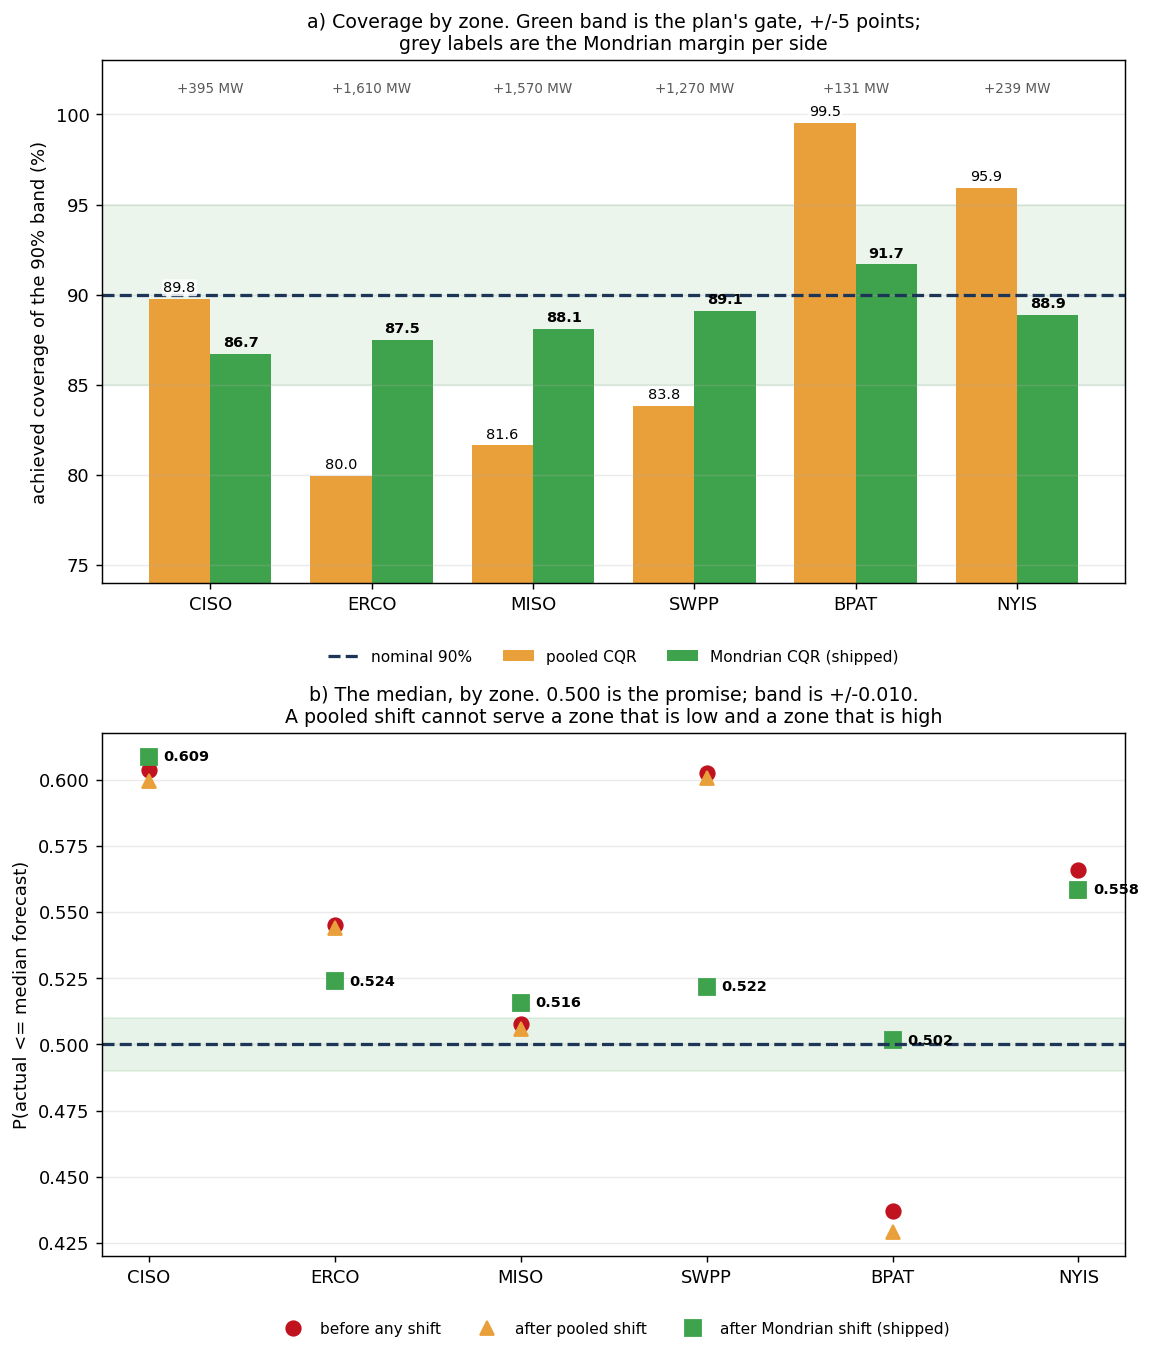

In [4]:
# WHAT: coverage and median calibration BY ZONE, pooled against Mondrian.
# WHY:  the guarantee the operator needs is per balancing authority, and this is the
#       only figure in the notebook that is drawn at that margin.
_zones = [z for z in cfg.ZONES if z in set(z_hold)]
_bp = by_zone_pooled.set_index("group").loc[_zones]
_bm = by_zone_cov.set_index("group").loc[_zones]
fig, axes = plt.subplots(2, 1, figsize=(9.0, 10.5))

ax = axes[0]
xs = np.arange(len(_zones)); w = 0.38
ax.bar(xs - w / 2, 100 * _bp["coverage"], w, color="#e9a03b", label="pooled CQR")
ax.bar(xs + w / 2, 100 * _bm["coverage"], w, color="#3fa34d", label="Mondrian CQR (shipped)")
ax.axhline(90, ls="--", color="#1d3557", lw=1.8, label="nominal 90%")
ax.axhspan(85, 95, color="#3fa34d", alpha=0.10, zorder=0)
for j, z in enumerate(_zones):
    ax.annotate(f"{100*_bp.loc[z,'coverage']:.1f}", (xs[j] - w / 2, 100 * _bp.loc[z, "coverage"]),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.85))
    ax.annotate(f"{100*_bm.loc[z,'coverage']:.1f}", (xs[j] + w / 2, 100 * _bm.loc[z, "coverage"]),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8,
                fontweight="bold")
    ax.annotate(f"{mm_add.get(z, mm_add[U.POOLED]):+,.0f} MW", (xs[j], 101.2),
                ha="center", fontsize=7.5, color="0.35")
ax.set_xticks(xs); ax.set_xticklabels(_zones)
ax.set_ylim(74, 103); ax.set_ylabel("achieved coverage of the 90% band (%)")
ax.set_title("a) Coverage by zone. Green band is the plan's gate, +/-5 points;\n"
             "grey labels are the Mondrian margin per side", fontsize=10.5)
ax.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3,
          frameon=False)
ax.grid(alpha=0.25, axis="y")

ax = axes[1]
_mz = med_zone.loc[_zones]
ax.plot(xs, _mz["before shift"], "o", ms=8, color="#c1121f", label="before any shift")
ax.plot(xs, _mz["pooled shift"], "^", ms=8, color="#e9a03b", label="after pooled shift")
ax.plot(xs, _mz["Mondrian shift"], "s", ms=9, color="#3fa34d", label="after Mondrian shift (shipped)")
ax.axhline(0.5, ls="--", color="#1d3557", lw=1.8)
ax.axhspan(0.49, 0.51, color="#3fa34d", alpha=0.12, zorder=0)
for j, z in enumerate(_zones):
    ax.annotate(f"{_mz.loc[z,'Mondrian shift']:.3f}", (xs[j], _mz.loc[z, "Mondrian shift"]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=8,
                fontweight="bold")
ax.set_xticks(xs); ax.set_xticklabels(_zones)
ax.set_ylabel("P(actual <= median forecast)")
ax.set_title("b) The median, by zone. 0.500 is the promise; band is +/-0.010.\n"
             "A pooled shift cannot serve a zone that is low and a zone that is high",
             fontsize=10.5)
ax.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3,
          frameon=False)
ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "06_mondrian_by_zone.png", bbox_inches="tight")
plt.show()


**Figure: `06_mondrian_by_zone.png`**

**What this shows:** (a) Coverage by zone, pooled vs Mondrian, with the ±5-point gate; (b) P(actual ≤ median forecast) by zone before any shift, after the pooled shift and after the Mondrian shift.

**What I see:** Pooled coverage spreads 19.6 points (BPAT 99.5 to ERCO 80.0). Mondrian brings it to 5.0 points (BPAT 91.7 to CISO 86.7), all zones inside the gate. The per-zone margins range from +131 MW (BPAT) to +1,610 MW (ERCO), against one pooled +619. For the median, Mondrian puts BPAT at 0.502 and moves SWPP to 0.522 and ERCO to 0.524, but CISO gets worse (0.604 → 0.609).

**What it means:** Mondrian fixes biases that differ across zones but not a bias that changes over time. CISO's median shift learned on the calibration block (2023-01-30 to 2024-02-06) is +22 MW, but in the holdout its median is too high: the sign reversed. NYIS (0.558), ERCO (0.524), SWPP (0.522) and MISO (0.516) also stay above 0.510.

**What I do:** Ship the Mondrian band and quote coverage per zone. The median test stays failing; the named fix is a rolling calibration window, not done here.

### 6.2b — Does the calibration hold at every horizon?

A three-level band (5th, 50th, 95th) fitted, calibrated Mondrian-by-zone and scored separately at h = 1, 24, 48 and 72, each on that horizon's champion. Conformal coverage assumes the calibration block and the holdout are exchangeable, and that may hold better at some leads than others.

   h= 1  raw 78.1% -> Mondrian CQR 85.9% (pooled 86.3%)   width    1,836 ->    2,272 MW   median 0.507 -> 0.517   worst zone CISO 80.8%


   h=24  raw 77.2% -> Mondrian CQR 88.8% (pooled 88.6%)   width    6,894 ->    8,757 MW   median 0.543 -> 0.539   worst zone CISO 86.8%


   h=48  raw 76.8% -> Mondrian CQR 89.4% (pooled 88.9%)   width    7,659 ->    9,982 MW   median 0.521 -> 0.521   worst zone BPAT 93.5%


   h=72  raw 76.0% -> Mondrian CQR 89.7% (pooled 89.1%)   width    7,846 ->   10,393 MW   median 0.510 -> 0.517   worst zone BPAT 93.8%

--- G3' by horizon: does the calibration hold away from h=24? ---


,coverage_raw,coverage_cqr,coverage_cqr_pooled,width_raw,width_cqr,width_cqr_pooled,winkler_raw,winkler_cqr,winkler_cqr_pooled,cqr_margin_mw,cqr_margin_pooled_mw,median_raw,median_cal,within_2pts,worst_zone,worst_zone_coverage,every_zone_within_5pts
horizon,,,,,,,,,,,,,,,,,
1,0.7805,0.8592,0.8631,1835.8,2271.9,2138.0,4442.9,4033.1,4227.9,218.1,151.1,0.507,0.517,False,CISO,0.8084,False
24,0.7722,0.8878,0.8861,6894.3,8756.9,8274.3,12989.5,11590.3,12195.0,931.5,690.0,0.543,0.539,True,CISO,0.8675,True
48,0.7683,0.8939,0.8893,7659.0,9982.0,9433.5,14550.8,12867.9,13565.5,1162.0,887.3,0.521,0.521,True,BPAT,0.9355,True
72,0.7601,0.8967,0.8910,7846.4,10392.5,9812.8,15198.3,13353.6,14058.2,1273.5,983.2,0.510,0.517,True,BPAT,0.9383,True



every horizon within +/-2 points of nominal: False
every (zone x horizon) cell within +/-5 points: False
worst horizon: h=1 at 85.9% (-4.1 pts)
   -> the guarantee does NOT transfer to every lead. Conformal coverage is marginal and
      rests on exchangeability between the calibration block and the holdout, and that
      assumption does not hold equally at every lead -- the worst horizon above is where it breaks. The
      per-horizon numbers are the ones to quote; the marginal figure hides this.


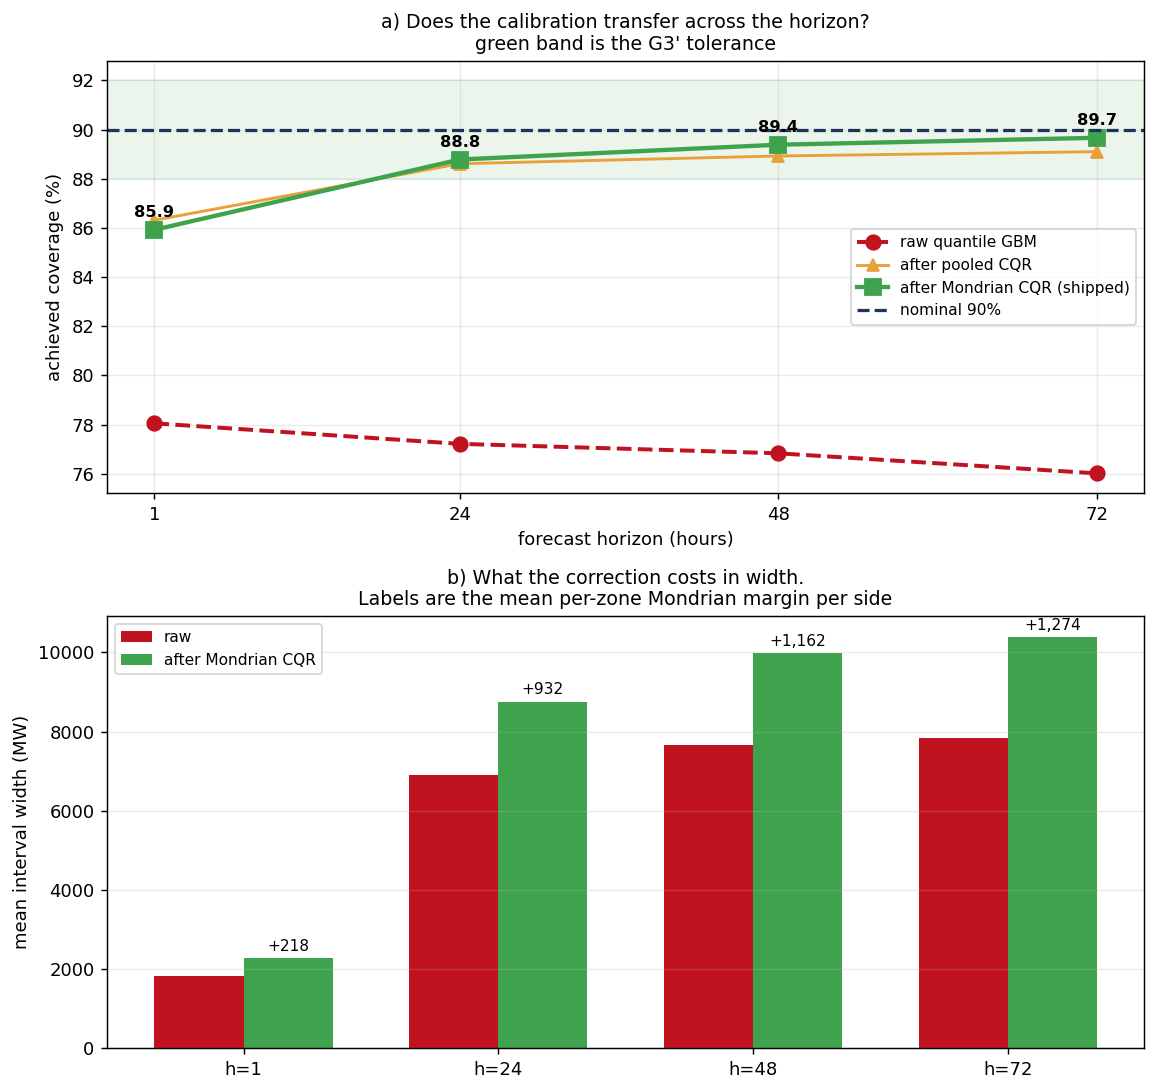

In [5]:
# WHAT: fit, calibrate and score a 90% band at every horizon, on that horizon's champion.
# WHY:  the conformal guarantee is marginal and rests on exchangeability. There is no
#       reason for the calibration block to be equally exchangeable with the holdout at
#       h=1 and at h=72, and quoting one number for all four would assume it is.
# COST: 3 quantile levels x 4 horizons = 12 fits on the fit block (no point model here).

per_h = R.require("nb04", "per_horizon_champions")
QS3 = [0.05, 0.5, 0.95]
rows_h = []
zone_margins_by_h = {}
for h in cfg.HORIZONS:
    ch = per_h[str(h)]["params"]
    mp = {k.replace("model__", ""): v for k, v in ch.items() if k.startswith("model__")}
    lg = tuple(ch["lag__lags"])

    def _qp(q):
        return P.make_supervised_pipeline(
            cfg.NUMERIC_FEATURES, lags=lg, roll_windows=tuple(ch["lag__roll_windows"]),
            k=ch["select__k"],
            model=HistGradientBoostingRegressor(loss="quantile", quantile=q,
                                                random_state=cfg.SEED, **mp))

    Qc_h, Qt_h = {}, {}
    for q in QS3:
        f = _qp(q).fit(sub_fit, y_fit)
        Qc_h[q], Qt_h[q] = f.predict(sub_cal), P.with_history(f, dev).predict(hold)
    Qc_h = U.rearrange(pd.DataFrame(Qc_h), QS3)
    Qt_h = U.rearrange(pd.DataFrame(Qt_h), QS3)

    # Mondrian by zone within each horizon -- the (zone x horizon) cell the
    # 08-29 log asked for. The pooled margin is kept beside it for reference.
    mm_h = U.mondrian_margins(y_cal, Qc_h[0.05], Qc_h[0.95], z_cal, alpha=ALPHA,
                              min_rows=MIN_CELL)
    lo_h, hi_h, _ = U.apply_mondrian(Qt_h[0.05], Qt_h[0.95], z_hold, mm_h)
    lo_hp, hi_hp = U.apply_cqr(Qt_h[0.05], Qt_h[0.95], mm_h[U.POOLED])
    ms_h = U.mondrian_level_shifts(y_cal, Qc_h[[0.5]], z_cal, min_rows=MIN_CELL)
    med_cal_h = Qt_h[0.5].to_numpy() + np.array(
        [ms_h.get(z, ms_h[U.POOLED])[0.5] for z in z_hold])

    raw = U.interval_report(yh, Qt_h[0.05], Qt_h[0.95], ALPHA)
    cal = U.interval_report(yh, lo_h, hi_h, ALPHA)
    pooled_h = U.interval_report(yh, lo_hp, hi_hp, ALPHA)
    bz = U.coverage_by(yh, lo_h, hi_h, z_hold).set_index("group")["coverage"]
    worst_z = str((bz - 0.9).abs().idxmax())
    zone_margins = {z: float(mm_h[z]) for z in cfg.ZONES if z in mm_h}
    rows_h.append({
        "horizon": h,
        "coverage_raw": raw["coverage"], "coverage_cqr": cal["coverage"],
        "coverage_cqr_pooled": pooled_h["coverage"],
        "width_raw": raw["mean_width"], "width_cqr": cal["mean_width"],
        "width_cqr_pooled": pooled_h["mean_width"],
        "winkler_raw": raw["winkler"], "winkler_cqr": cal["winkler"],
        "winkler_cqr_pooled": pooled_h["winkler"],
        "cqr_margin_mw": float(np.mean(list(zone_margins.values()))),
        "cqr_margin_pooled_mw": float(mm_h[U.POOLED]),
        "median_raw": U.median_bias(yh, Qt_h[0.5]),
        "median_cal": U.median_bias(yh, med_cal_h),
        "within_2pts": bool(abs(cal["coverage"] - 0.9) <= 0.02),
        "worst_zone": worst_z, "worst_zone_coverage": float(bz[worst_z]),
        "every_zone_within_5pts": bool((bz - 0.9).abs().max() <= 0.05),
    })
    zone_margins_by_h[str(h)] = zone_margins
    print(f"   h={h:>2}  raw {raw['coverage']:.1%} -> Mondrian CQR {cal['coverage']:.1%} "
          f"(pooled {pooled_h['coverage']:.1%})   "
          f"width {raw['mean_width']:8,.0f} -> {cal['mean_width']:8,.0f} MW   "
          f"median {U.median_bias(yh, Qt_h[0.5]):.3f} -> {U.median_bias(yh, med_cal_h):.3f}   "
          f"worst zone {worst_z} {bz[worst_z]:.1%}")

ch_cov = pd.DataFrame(rows_h).set_index("horizon")
print("\n--- G3' by horizon: does the calibration hold away from h=24? ---")
display(ch_cov.round({"coverage_raw": 4, "coverage_cqr": 4, "coverage_cqr_pooled": 4,
                      "width_raw": 1, "width_cqr": 1, "width_cqr_pooled": 1,
                      "winkler_raw": 1, "winkler_cqr": 1, "winkler_cqr_pooled": 1,
                      "cqr_margin_mw": 1, "cqr_margin_pooled_mw": 1,
                      "median_raw": 3, "median_cal": 3, "worst_zone_coverage": 4}))

all_within = bool(ch_cov["within_2pts"].all())
worst_h = int(ch_cov["coverage_cqr"].sub(0.9).abs().idxmax())
print(f"\nevery horizon within +/-2 points of nominal: {all_within}")
print(f"every (zone x horizon) cell within +/-5 points: "
      f"{bool(ch_cov['every_zone_within_5pts'].all())}")
print(f"worst horizon: h={worst_h} at {ch_cov.loc[worst_h, 'coverage_cqr']:.1%} "
      f"({100*(ch_cov.loc[worst_h, 'coverage_cqr'] - 0.9):+.1f} pts)")
print("   -> " + (
    "the correction transfers across the horizon. G3' is met at every lead, not "
    "only at\n      the one it was fitted on."
    if all_within else
    "the guarantee does NOT transfer to every lead. Conformal coverage is marginal "
    "and\n      rests on exchangeability between the calibration block and the "
    "holdout, and that\n      assumption does not hold equally at every lead -- the worst "
    "horizon above is where it breaks. The\n      per-horizon numbers are the ones to quote; the "
    "marginal figure hides this."))

fig, axes = plt.subplots(2, 1, figsize=(9.0, 8.5))
ax = axes[0]
ax.plot(ch_cov.index, 100 * ch_cov["coverage_raw"], "o--", lw=2.2, ms=8,
        color="#c1121f", label="raw quantile GBM")
ax.plot(ch_cov.index, 100 * ch_cov["coverage_cqr_pooled"], "^-", lw=1.6, ms=7,
        color="#e9a03b", label="after pooled CQR")
ax.plot(ch_cov.index, 100 * ch_cov["coverage_cqr"], "s-", lw=2.4, ms=9,
        color="#3fa34d", label="after Mondrian CQR (shipped)")
ax.axhline(90, ls="--", color="#1d3557", lw=1.8, label="nominal 90%")
ax.axhspan(88, 92, color="#3fa34d", alpha=0.10, zorder=0)
for h in ch_cov.index:
    ax.annotate(f"{100*ch_cov.loc[h,'coverage_cqr']:.1f}",
                (h, 100 * ch_cov.loc[h, "coverage_cqr"]), xytext=(0, 7),
                textcoords="offset points", ha="center", fontsize=9,
                fontweight="bold")
ax.set_xticks(list(cfg.HORIZONS)); ax.set_xlabel("forecast horizon (hours)")
ax.set_ylabel("achieved coverage (%)")
ax.set_title("a) Does the calibration transfer across the horizon?\n"
             "green band is the G3' tolerance", fontsize=10.5)
ax.legend(fontsize=8.5); ax.grid(alpha=0.25)

ax = axes[1]
w = 0.35
xs = np.arange(len(ch_cov))
ax.bar(xs - w / 2, ch_cov["width_raw"], w, color="#c1121f", label="raw")
ax.bar(xs + w / 2, ch_cov["width_cqr"], w, color="#3fa34d", label="after Mondrian CQR")
for j, h in enumerate(ch_cov.index):
    ax.annotate(f"{ch_cov.loc[h,'cqr_margin_mw']:+,.0f}",
                (xs[j] + w / 2, ch_cov.loc[h, "width_cqr"]), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=8.5)
ax.set_xticks(xs); ax.set_xticklabels([f"h={h}" for h in ch_cov.index])
ax.set_ylabel("mean interval width (MW)")
ax.set_title("b) What the correction costs in width.\nLabels are the mean per-zone "
             "Mondrian margin per side", fontsize=10.5)
ax.legend(fontsize=8.5); ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "06_coverage_by_horizon.png", bbox_inches="tight")
plt.show()

def _jsonable(v):
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, str):
        return v
    return float(v)


R.save("nb06", {"coverage_by_horizon": {
    str(h): {k: _jsonable(v) for k, v in ch_cov.loc[h].items()} for h in ch_cov.index},
    "mondrian_margins_by_horizon_mw": zone_margins_by_h,
    "g3_prime_all_horizons_within_2pts": all_within,
    "g3_prime_every_cell_within_5pts": bool(ch_cov["every_zone_within_5pts"].all()),
    "g3_prime_worst_horizon": worst_h,
});


**Figure: `06_coverage_by_horizon.png`**

**What I see:** Mondrian coverage is 85.9% at h=1 (worst zone CISO 80.8%), 88.8% at h=24, 89.4% at h=48 and 89.7% at h=72. Mondrian improves Winkler at every horizon (h=1: 4,228 → 4,033). Widths grow from 2,272 MW at h=1 to 10,393 MW at h=72. (The h=24 row differs slightly from §6.2's 88.7% because only three levels are fitted here.)

**What it means:** The correction carries over to the long horizons but not to h=1, where the band is narrowest and the CISO drift is the largest relative miss.

**What I do:** Judge coverage on the worst horizon. On that rule it fails at h=1 (85.9%), and the ±5-point per-zone gate also fails there. h=1 is reported as the open defect.

### 6.3 — Weather uncertainty from injected noise

The 90% interval refitted at every horizon with and without Gaussian noise on temperature, scaled to a published 1994–95 forecast-error curve. Only `temp` is perturbed; humidity, wind and cloud cover stay at reanalysis values. Section 6.3b replaces this with the weather forecast actually issued; this version is kept for comparison.

  h= 1 scale=0  width   1,985 MW  coverage 82.3%  sigma 0.00 C


  h= 1 scale=1  width   1,985 MW  coverage 82.3%  sigma 0.00 C


  h=24 scale=0  width   7,124 MW  coverage 80.2%  sigma 0.00 C


  h=24 scale=1  width   7,125 MW  coverage 80.3%  sigma 2.33 C


  h=48 scale=0  width   7,850 MW  coverage 79.5%  sigma 0.00 C


  h=48 scale=1  width   7,840 MW  coverage 79.5%  sigma 2.92 C


  h=72 scale=0  width   8,026 MW  coverage 79.3%  sigma 0.00 C


  h=72 scale=1  width   8,024 MW  coverage 79.1%  sigma 3.72 C


,width_scale0,width_scale1,widening_mw,widening_pct
horizon,,,,
1,1985.3,1985.3,0.0,0.0
24,7123.8,7124.8,1.1,0.0
48,7850.3,7840.2,-10.0,-0.1
72,8025.7,8023.7,-2.1,-0.0


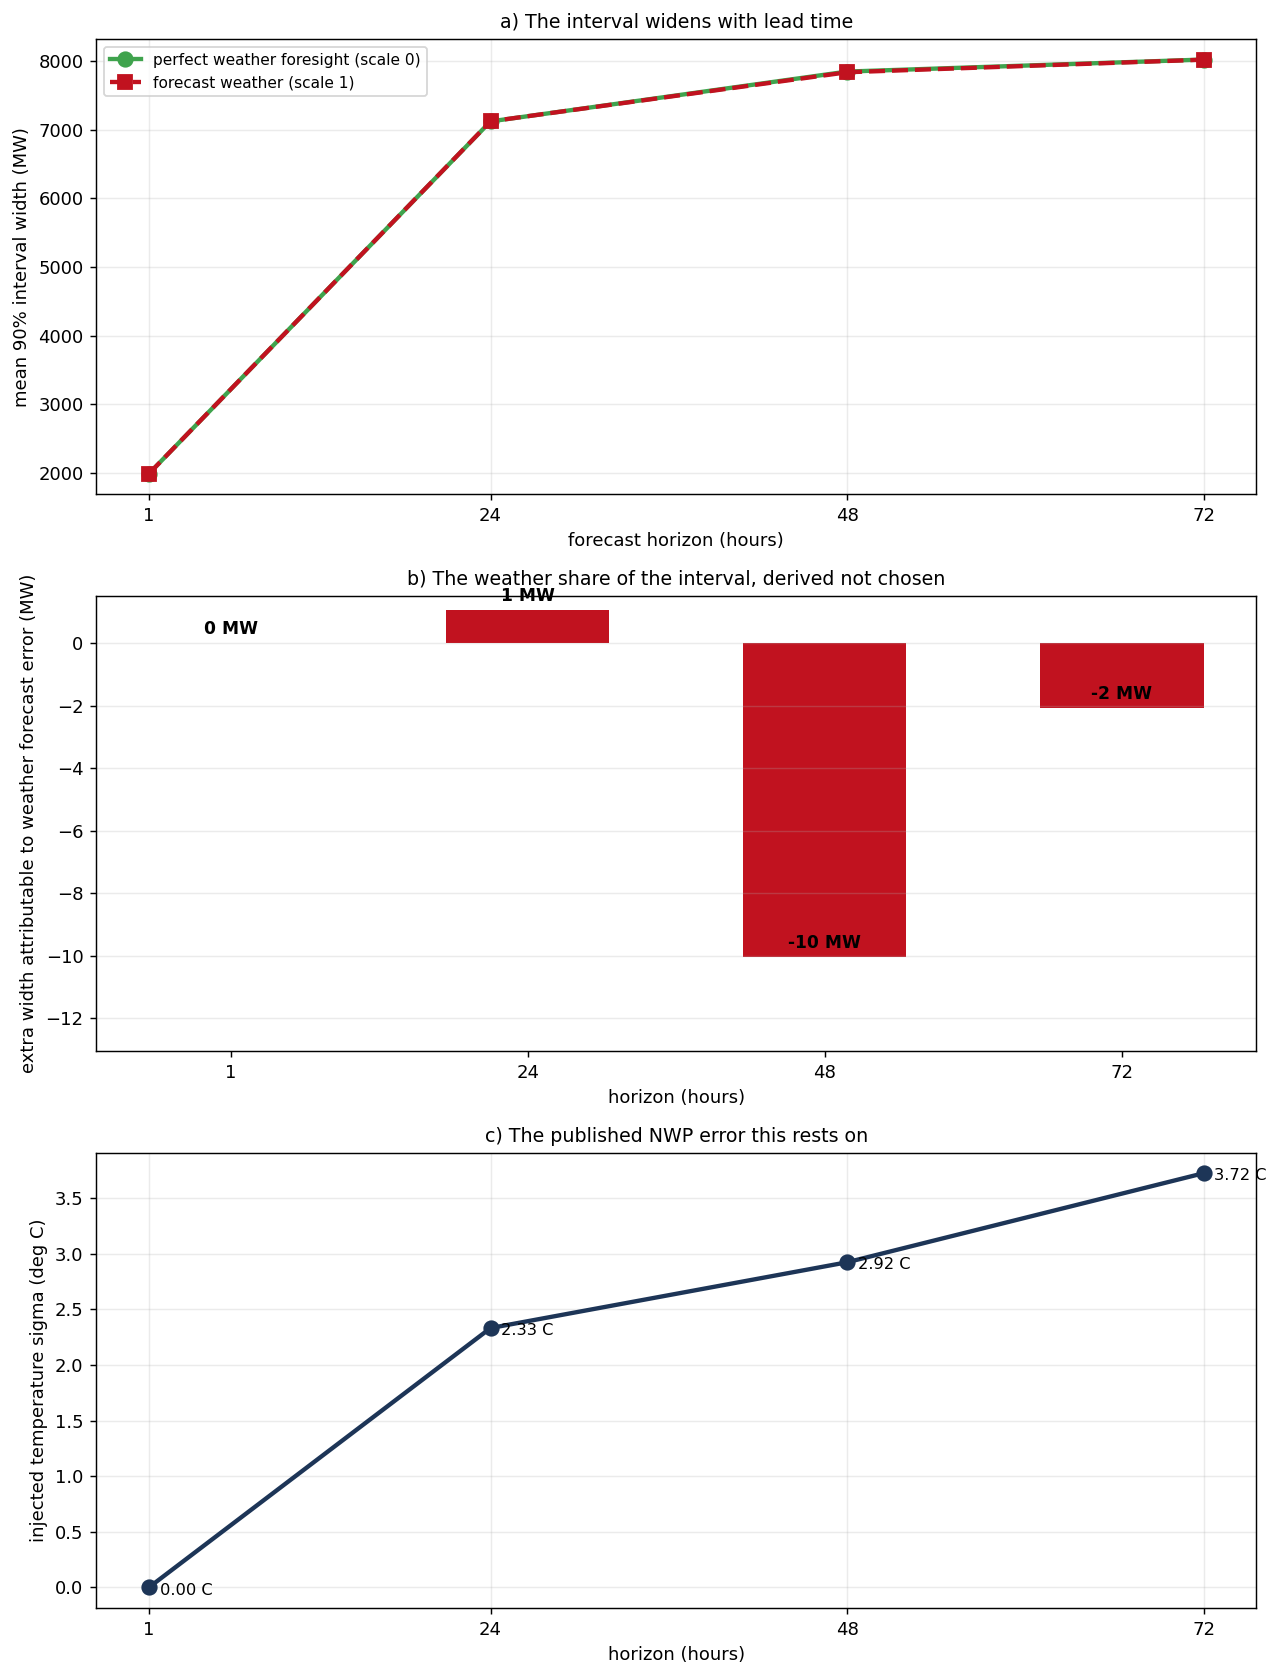

In [6]:
# WHAT: how much wider the interval has to be because the WEATHER is forecast rather
#       than observed, measured separately at each horizon.
# WHY:  this is the section the project's name points at. cfg says it plainly --
#       "notebook 04 sweeps it; notebook 06 uses the result to widen intervals with the
#       horizon". The widening is DERIVED from the measured scale-0/scale-1 gap, not
#       chosen. A hand-picked factor would make the interval a decoration.
#
# HOW THE NOISE IS BUILT. cfg.NWP_TEMP_MAE_C_BY_LEAD_DAY carries published NWP
# temperature error by lead day (1.861 C at day 1 rising to 2.972 at day 3);
# WeatherForecastNoise converts MAE to a Gaussian sigma and perturbs the
# CONTEMPORANEOUS weather only -- the lagged weather is observed at the origin and
# must not be degraded.
#
# THE LIMITATION, STATED HERE RATHER THAN IN A FOOTNOTE. Only `temp` is perturbed,
# because temperature is the only variable this project has a published error curve
# for. Humidity, wind speed and CLOUD COVER are left at reanalysis truth, and cloud
# cover is the dominant driver of the midday solar belly -- the duck curve itself.
# Every widening below is therefore a LOWER BOUND on the true weather uncertainty,
# and the bound is loosest exactly where the duck curve lives. Inventing an MAE for
# cloud cover to close the gap would be fabricating the one kind of number this
# project refuses to fabricate.
HORIZONS = sorted(cfg.LAGS_BY_HORIZON)
rows = []
for h in HORIZONS:
    h_lags = cfg.lags_for(h)
    for scale in (0.0, 1.0):
        lo = quantile_pipe(0.05, noise_scale=scale, lags=h_lags).fit(dev, y_dev).predict(hold)
        hi = quantile_pipe(0.95, noise_scale=scale, lags=h_lags).fit(dev, y_dev).predict(hold)
        med = quantile_pipe(0.50, noise_scale=scale, lags=h_lags).fit(dev, y_dev).predict(hold)
        rows.append({
            "horizon": h, "noise_scale": scale,
            "mean_width": float(np.mean(hi - lo)),
            "coverage": float(((yh >= lo) & (yh <= hi)).mean()),
            "winkler": U.winkler(yh, lo, hi),
            "mae_median": float(np.mean(np.abs(yh - med))),
            "sigma_c": float(P.WeatherForecastNoise(horizon=h, scale=scale).sigma_),
        })
        print(f"  h={h:2d} scale={scale:.0f}  width {rows[-1]['mean_width']:7,.0f} MW  "
              f"coverage {rows[-1]['coverage']:.1%}  sigma {rows[-1]['sigma_c']:.2f} C")

wdf = pd.DataFrame(rows)
piv = wdf.pivot(index="horizon", columns="noise_scale", values="mean_width")
piv.columns = ["width_scale0", "width_scale1"]
piv["widening_mw"] = piv["width_scale1"] - piv["width_scale0"]
piv["widening_pct"] = 100 * piv["widening_mw"] / piv["width_scale0"]
display(piv.round(1))

fig, axes = plt.subplots(3, 1, figsize=(10.0, 13.0))
ax = axes[0]
ax.plot(piv.index, piv["width_scale0"], "o-", lw=2.4, ms=8, color="#3fa34d",
        label="perfect weather foresight (scale 0)")
ax.plot(piv.index, piv["width_scale1"], "s--", lw=2.4, ms=8, color="#c1121f",
        label="forecast weather (scale 1)")
ax.fill_between(piv.index, piv["width_scale0"], piv["width_scale1"],
                color="#c1121f", alpha=0.13)
ax.set_xlabel("forecast horizon (hours)"); ax.set_ylabel("mean 90% interval width (MW)")
ax.set_title("a) The interval widens with lead time", fontsize=10.5)
ax.set_xticks(piv.index); ax.legend(fontsize=8.5); ax.grid(alpha=0.25)

ax = axes[1]
ax.bar([str(h) for h in piv.index], piv["widening_mw"], color="#c1121f", width=0.55)
for i, v in enumerate(piv["widening_mw"]):
    ax.annotate(f"{v:,.0f} MW", (i, v), xytext=(0, 5), textcoords="offset points",
                ha="center", fontsize=9.5, fontweight="bold")
_v = piv["widening_mw"]
ax.set_ylim(min(0, float(_v.min()) * 1.3), max(0, float(_v.max()) * 1.45))   # room for the labels
ax.set_xlabel("horizon (hours)")
ax.set_ylabel("extra width attributable to weather forecast error (MW)")
ax.set_title("b) The weather share of the interval, derived not chosen", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")

ax = axes[2]
sig = wdf[wdf.noise_scale == 1.0].set_index("horizon")["sigma_c"]
ax.plot(sig.index, sig.values, "o-", lw=2.4, ms=8, color="#1d3557")
for h, v in sig.items():
    ax.annotate(f"{v:.2f} C", (h, v), xytext=(6, -4), textcoords="offset points",
                fontsize=9)
ax.set_xlabel("horizon (hours)")
ax.set_ylabel("injected temperature sigma (deg C)")
ax.set_title("c) The published NWP error this rests on", fontsize=10.5)
ax.set_xticks(sig.index); ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "06_weather_uncertainty.png", bbox_inches="tight")
plt.show()

R.save("nb06", {
    "weather_widening": wdf.to_dict("records"),
    "width_by_horizon_scale0": {str(h): float(v) for h, v in piv["width_scale0"].items()},
    "width_by_horizon_scale1": {str(h): float(v) for h, v in piv["width_scale1"].items()},
    "widening_mw_by_horizon": {str(h): float(v) for h, v in piv["widening_mw"].items()},
    "widening_pct_by_horizon": {str(h): float(v) for h, v in piv["widening_pct"].items()},
    "weather_noise_covers_columns": ["temp"],
    "weather_widening_is_a_lower_bound": True,
    "lower_bound_reason": ("Only temp is perturbed -- it is the only variable with a "
                           "published NWP error curve here. Humidity, wind_speed and "
                           "cloud_cover stay at reanalysis truth, and cloud_cover "
                           "drives the midday solar belly, so the bound is loosest "
                           "exactly where the duck curve is."),
});


**Figure: `06_weather_uncertainty.png`**

**What I see:** Width without noise is 1,985 → 7,124 → 7,850 → 8,026 MW at h = 1, 24, 48, 72. The noise (sigmas 0.00 → 2.33 → 2.92 → 3.72 °C) changes it by 0 → +1.1 → −10.0 → −2.1 MW, effectively zero. Coverage at h=24 is 80.2% without noise and 80.3% with it.

**What it means:** The interval grows with horizon because the recent lags are lost (3.6× from h=1 to h=24), not because of weather. The tree model averages unstructured noise away, and cloud cover is not perturbed, so this is a lower bound.

**What I do:** Report this as a negative result, not as "the weather share". The operational number comes from §6.3b.

### 6.3b — The weather an operator actually holds (G6)

The holdout is re-scored with the weather forecast issued at each lead (day-1 run for h=24, day-2 for h=48, day-3 for h=72) and compared with scoring on reanalysis. The model is trained on reanalysis in both cases. Only same-hour weather is swapped; lagged weather was already observed at the forecast origin. Runs are daily, so the actual lead is 24N to 24N+24 hours and each penalty is an upper bound. Predictions recorded before the run: the penalty grows with horizon, and it is concentrated on duck days.

forecast weather: 144,720 rows, leads [1, 2, 3], columns ['temp', 'cloud_cover', 'ghi', 'wind_speed_100m', 'humidity', 'wind_speed']


   h= 1  no archived lead shorter than a day — reanalysis stands in


   h=24  lead day 1   reanalysis   2,159.6 MW   operational   2,149.5 MW   penalty    -10.1 MW (-0.47%)   swap coverage 0.995


   h=48  lead day 2   reanalysis   2,389.7 MW   operational   2,391.6 MW   penalty     +1.9 MW (+0.08%)   swap coverage 0.995


   h=72  lead day 3   reanalysis   2,470.8 MW   operational   2,507.8 MW   penalty    +37.0 MW (+1.50%)   swap coverage 0.994

--- G6: holdout MAE under reanalysis and under the forecast as issued ---


,lead_day,mae_reanalysis,mae_operational,penalty_mw,penalty_pct,p95_reanalysis,p95_operational,spread_widening_pct,note,swap_coverage
horizon,,,,,,,,,,
1,NaN,547.1,547.1,0.0,0.000,1884.8,1884.8,0.000,no sub-daily forecast archive; nowcast ~ obser...,NaN
24,1.0,2159.6,2149.5,-10.1,-0.467,6962.7,6907.3,-0.795,,0.995306
48,2.0,2389.7,2391.6,1.9,0.079,7698.0,7723.2,0.328,,0.994799
72,3.0,2470.8,2507.8,37.0,1.499,7979.9,8126.8,1.841,,0.994292



P-G6.1  degradation grows with the horizon: False   (MAE penalty by horizon: {1: 0.0, 24: -0.47, 48: 0.08, 72: 1.5})
P-G6.2  the modelled -0.03% at h=72 was a widening of the
        INTERVAL under injected temperature noise, so the comparable
        measurement is the widening of the error SPREAD, not of the MAE.
        measured p95|error| widening at h=72: +1.84%
        measured MAE penalty at h=72:        +1.50%
        -> ABOVE this run's modelled floor (the prediction was registered against an earlier run's 6.26%; see the markdown).



--- P-G6.3: the weather penalty by regime ---


horizon,24,48,72
regime,,,
0 winter-shaped,-18.4,12.8,71.1
1 conventional,2.2,28.2,64.0
2 DUCK,-24.1,-42.5,-17.2
unlabelled,-121.5,-238.1,-318.4


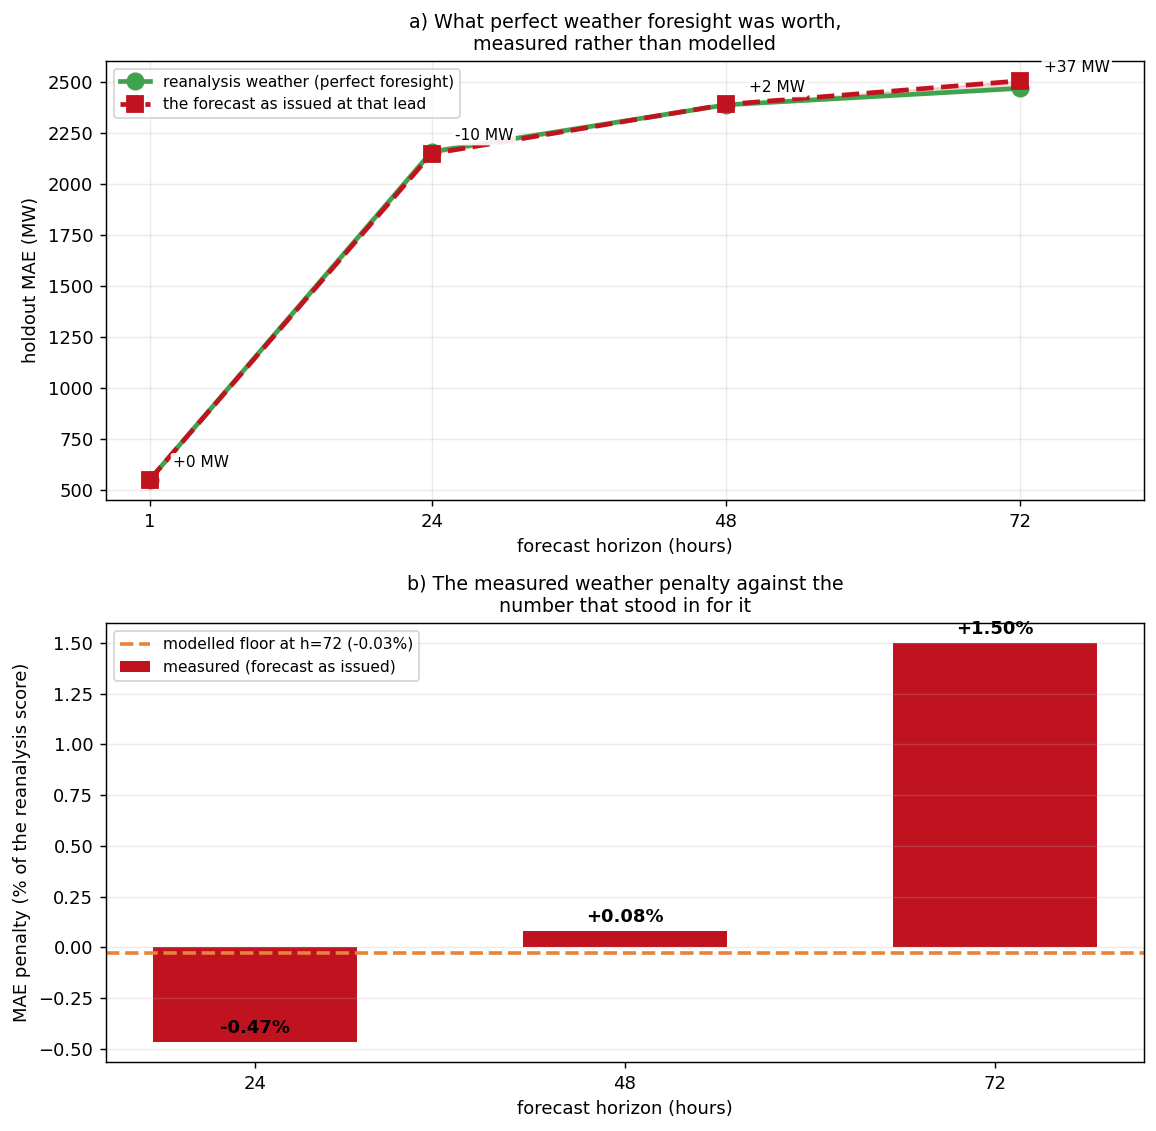

In [7]:
# WHAT: re-score the holdout on the weather forecast issued at each lead time.
# WHY:  G6. Every result before 2026-08-23 gave the model perfect weather foresight.
#       This measures what that was worth instead of bounding it from a 1990s curve.
# NOTE: only the SAME-HOUR weather is swapped. A lag L >= h is observed at the
#       origin and keeps its reanalysis value -- see P.WeatherForecastSwap.

from src.sources import FORECAST_LEAD_BY_HORIZON

FC_PATH = cfg.DATA_PROC / "weather_forecast_holdout.parquet"
fc_all = pd.read_parquet(FC_PATH)
fc_all[cfg.TIME_COL] = pd.to_datetime(fc_all[cfg.TIME_COL])
SWAP_COLS = [c for c in fc_all.columns
             if c not in (cfg.TIME_COL, cfg.GROUP_COL, "lead_day")]
print(f"forecast weather: {len(fc_all):,} rows, leads "
      f"{sorted(fc_all['lead_day'].unique())}, columns {SWAP_COLS}")

ops = []
ops_pred = {}
for h in cfg.HORIZONS:
    ch = per_h[str(h)]["params"]
    mp = {k.replace("model__", ""): v for k, v in ch.items() if k.startswith("model__")}
    lg = tuple(ch["lag__lags"])
    lead = FORECAST_LEAD_BY_HORIZON.get(h)

    def _fit(forecast=None):
        pipe = P.make_supervised_pipeline(
            cfg.NUMERIC_FEATURES, lags=lg, roll_windows=tuple(ch["lag__roll_windows"]),
            k=ch["select__k"], weather_forecast=forecast,
            weather_forecast_columns=SWAP_COLS if forecast is not None else None,
            model=HistGradientBoostingRegressor(random_state=cfg.SEED, **mp))
        return pipe.fit(dev, y_dev)

    # The model TRAINS on reanalysis in both arms. Only scoring changes. Training on
    # forecasts would need forecast weather back to 2019, which the archive does not
    # have, and would confound "the forecast is wrong" with "the model saw different
    # training data".
    pipe_re = _fit(None)
    mae_re = float(mean_absolute_error(y_hold, pipe_re.predict(hold)))

    if lead is None:
        # h=1. The archive's shortest lead is a whole day, and an hour-ahead weather
        # forecast is close to observation. Inventing a sub-daily degradation would
        # fabricate the one number this whole section exists to stop fabricating.
        p_re = pipe_re.predict(hold)
        ops.append({"horizon": h, "lead_day": None, "mae_reanalysis": mae_re,
                    "mae_operational": mae_re, "penalty_mw": 0.0, "penalty_pct": 0.0,
                    "p95_reanalysis": float(np.quantile(np.abs(y_hold - p_re), 0.95)),
                    "p95_operational": float(np.quantile(np.abs(y_hold - p_re), 0.95)),
                    "spread_widening_pct": 0.0,
                    "note": "no sub-daily forecast archive; nowcast ~ observation"})
        ops_pred[h] = p_re
        print(f"   h={h:>2}  no archived lead shorter than a day — reanalysis stands in")
        continue

    fc = fc_all[fc_all["lead_day"] == lead]
    pipe_op = _fit(fc)
    p_op = pipe_op.predict(hold)
    ops_pred[h] = p_op
    mae_op = float(mean_absolute_error(y_hold, p_op))
    swap = pipe_op.named_steps["swap"]
    # THE COMPARABLE QUANTITY. Section 6.3's h=72 figure (0.35% now, 6.26% in an
    # earlier run) is a widening of the
    # INTERVAL, not a rise in MAE, and quoting one against the other would be
    # comparing two different things and calling it a check. p95 of the absolute
    # error is the spread of the error distribution -- the quantity an interval is
    # drawn around and the quantity reserve is sized from -- so it is what the
    # modelled floor can honestly be held against.
    p95_re = float(np.quantile(np.abs(y_hold - pipe_re.predict(hold)), 0.95))
    p95_op = float(np.quantile(np.abs(y_hold - p_op), 0.95))
    ops.append({"horizon": h, "lead_day": int(lead),
                "mae_reanalysis": mae_re, "mae_operational": mae_op,
                "penalty_mw": mae_op - mae_re,
                "penalty_pct": 100 * (mae_op - mae_re) / mae_re,
                "p95_reanalysis": p95_re, "p95_operational": p95_op,
                "spread_widening_pct": 100 * (p95_op - p95_re) / p95_re,
                "swap_coverage": float(swap.coverage_),
                "note": ""})
    print(f"   h={h:>2}  lead day {lead}   reanalysis {mae_re:9,.1f} MW   "
          f"operational {mae_op:9,.1f} MW   penalty {mae_op - mae_re:+8,.1f} MW "
          f"({100*(mae_op-mae_re)/mae_re:+.2f}%)   swap coverage {swap.coverage_:.3f}")

op = pd.DataFrame(ops).set_index("horizon")
print("\n--- G6: holdout MAE under reanalysis and under the forecast as issued ---")
display(op.round({"mae_reanalysis": 1, "mae_operational": 1, "penalty_mw": 1,
                  "penalty_pct": 3, "p95_reanalysis": 1, "p95_operational": 1,
                  "spread_widening_pct": 3}))

# --- the predictions registered in advance, scored ----------------------
# COMPARE LIKE WITH LIKE. Section 6.3's h=72 figure (0.35% now, 6.26% in an
# earlier run) is a widening of the
# INTERVAL under injected temperature noise, not a rise in MAE. Quoting one against
# the other would be comparing two different quantities and calling it a check. p95
# of the absolute error is the spread of the error distribution -- the quantity an
# interval is drawn around, and the quantity reserve is sized from -- so it is
# what the modelled floor can honestly be held against. The MAE penalty is reported
# beside it because it is the number an operator feels.
_wid = R.get("nb06", "widening_pct_by_horizon", default={})
modelled_floor = float(_wid.get("72", 6.2616))
p72 = float(op.loc[72, "penalty_pct"])
s72 = float(op.loc[72, "spread_widening_pct"])
print(f"\nP-G6.1  degradation grows with the horizon: "
      f"{bool(op['penalty_pct'].is_monotonic_increasing)}"
      f"   (MAE penalty by horizon: "
      f"{ {int(h): round(float(op.loc[h, 'penalty_pct']), 2) for h in op.index} })")
print(f"P-G6.2  the modelled {modelled_floor:.2f}% at h=72 was a widening of the")
print(f"        INTERVAL under injected temperature noise, so the comparable")
print(f"        measurement is the widening of the error SPREAD, not of the MAE.")
print(f"        measured p95|error| widening at h=72: {s72:+.2f}%")
print(f"        measured MAE penalty at h=72:        {p72:+.2f}%")
print("        -> " + ("ABOVE this run's modelled floor (the prediction was registered against an "
                          "earlier run's 6.26%; see the markdown)." if s72 > modelled_floor
      else "BELOW the modelled floor. That is a FINDING, not a failure: the Brooks "
           "curve\n           is 1994-95 vintage and its first documented failure "
           "mode is 'TOO BIG,\n           numerical weather prediction has improved "
           "since'. Notebook 00 measured\n           exactly that -- modern day-1 "
           "temperature error is 1.35 C against the\n           curve's 1.86 C. The "
           "floor was built to be conservative and it was."))

# --- P-G6.3: is the damage concentrated in the duck regime? -----------------
by_reg = None
if lab_path.exists():
    reg = hold_ctx["regime"].to_numpy()
    rows_r = []
    for h in cfg.HORIZONS:
        if op.loc[h, "lead_day"] is None or pd.isna(op.loc[h, "lead_day"]):
            continue
        err_op = np.abs(y_hold - ops_pred[h])
        ch = per_h[str(h)]["params"]
        mp = {k.replace("model__", ""): v for k, v in ch.items() if k.startswith("model__")}
        pipe_re = P.make_supervised_pipeline(
            cfg.NUMERIC_FEATURES, lags=tuple(ch["lag__lags"]),
            roll_windows=tuple(ch["lag__roll_windows"]), k=ch["select__k"],
            model=HistGradientBoostingRegressor(random_state=cfg.SEED, **mp)).fit(dev, y_dev)
        err_re = np.abs(y_hold - pipe_re.predict(hold))
        for r in pd.unique(reg):
            m = reg == r
            rows_r.append({"horizon": h, "regime": r, "rows": int(m.sum()),
                           "mae_reanalysis": float(err_re[m].mean()),
                           "mae_operational": float(err_op[m].mean()),
                           "penalty_mw": float(err_op[m].mean() - err_re[m].mean())})
    by_reg = pd.DataFrame(rows_r)
    print("\n--- P-G6.3: the weather penalty by regime ---")
    display(by_reg.pivot(index="regime", columns="horizon",
                         values="penalty_mw").round(1))

fig, axes = plt.subplots(2, 1, figsize=(9.0, 8.8))
ax = axes[0]
ax.plot(op.index, op["mae_reanalysis"], "o-", lw=2.6, ms=9, color="#3fa34d",
        label="reanalysis weather (perfect foresight)")
ax.plot(op.index, op["mae_operational"], "s--", lw=2.6, ms=9, color="#c1121f",
        label="the forecast as issued at that lead")
ax.fill_between(op.index, op["mae_reanalysis"], op["mae_operational"],
                color="#c1121f", alpha=0.15)
for h in op.index:
    ax.annotate(f"{op.loc[h,'penalty_mw']:+,.0f} MW",
                (h, (op.loc[h, "mae_reanalysis"] + op.loc[h, "mae_operational"]) / 2),
                xytext=(13, 7), textcoords="offset points", fontsize=8.5, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
ax.set_xticks(list(cfg.HORIZONS)); ax.set_xlabel("forecast horizon (hours)")
ax.set_xlim(right=max(cfg.HORIZONS) * 1.14)      # room for the h=72 label, which ran off the frame
ax.set_ylabel("holdout MAE (MW)"); ax.legend(fontsize=8.5)
ax.set_title("a) What perfect weather foresight was worth,\nmeasured rather than "
             "modelled", fontsize=10.5)
ax.grid(alpha=0.25)

ax = axes[1]
xs = [h for h in op.index if op.loc[h, "lead_day"] is not None
      and not pd.isna(op.loc[h, "lead_day"])]
ax.bar([str(h) for h in xs], [op.loc[h, "penalty_pct"] for h in xs], 0.55,
       color="#c1121f", label="measured (forecast as issued)")
ax.axhline(modelled_floor, ls="--", color="#e8833a", lw=2,
           label=f"modelled floor at h=72 ({modelled_floor:.2f}%)")
for j, h in enumerate(xs):
    ax.annotate(f"{op.loc[h,'penalty_pct']:+.2f}%", (j, op.loc[h, "penalty_pct"]),
                xytext=(0, 5), textcoords="offset points", ha="center",
                fontsize=10, fontweight="bold")
ax.set_xlabel("forecast horizon (hours)")
ax.set_ylabel("MAE penalty (% of the reanalysis score)")
ax.set_title("b) The measured weather penalty against the\nnumber that stood in "
             "for it", fontsize=10.5)
ax.legend(fontsize=8.5); ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "06_operational_weather.png", bbox_inches="tight")
plt.show()

# Persisted for reserve sizing: reserve should be sized off the error distribution an
# operator would actually face, not off the one perfect foresight produces.
opd = pd.DataFrame({
    "timestamp": np.tile(hold[cfg.TIME_COL].to_numpy(), len(cfg.HORIZONS)),
    "zone": np.tile(hold[cfg.GROUP_COL].to_numpy(), len(cfg.HORIZONS)),
    "horizon": np.repeat(list(cfg.HORIZONS), len(hold)),
    "y_true": np.tile(y_hold, len(cfg.HORIZONS)),
    "y_pred_operational": np.concatenate([ops_pred[h] for h in cfg.HORIZONS]),
})
opd.to_parquet(cfg.DATA_PROC / "uncertainty" / "operational_weather_predictions.parquet",
               index=False)

R.save("nb06", {"operational_weather_by_horizon": {
    str(h): {k: (None if (isinstance(v, float) and pd.isna(v)) else
                 (float(v) if isinstance(v, (int, float, np.floating)) else v))
             for k, v in op.loc[h].items()} for h in op.index},
    "operational_weather_penalty_pct_h72": p72,
    "operational_weather_spread_widening_pct_h72": s72,
    "operational_weather_modelled_floor_pct": float(modelled_floor),
    "operational_weather_by_regime": (by_reg.to_dict("records")
                                      if by_reg is not None else None),
    "operational_weather_lead_caveat": (
        "previous_dayN is the run issued N days earlier and runs are daily, so the "
        "effective lead for a given hour is 24N to 24N+24 hours. Every penalty here "
        "is an UPPER bound on the true penalty at h=24N."),
});


**Figure: `06_operational_weather.png`**

**What I see:** The MAE penalty for using issued weather is −10.1 MW at h=24, +1.9 MW at h=48 and +37.0 MW (1.50%) at h=72; the p95 error spread widens 1.84% at h=72. The h=1 row is reanalysis standing in (no sub-daily archive), so its zero is by construction. Both predictions failed: the penalty does not grow steadily with horizon, and on duck days it is negative at every lead (−24.1, −42.5, −17.2 MW); it is carried by conventional days and, at h=48 and h=72, winter-shaped days.

**What it means:** Perfect weather foresight was worth little before three days, and at h=72 the penalty is small but real (1.50% of MAE). This is an upper bound because the issued forecast is on average older than the nominal lead.

**What I do:** Report the penalty as an upper bound, next to the modelled −0.03% from §6.3. Read the h=24 and h=48 values as no measurable penalty, not as a gain.

### 6.4 — Encodings and audiences

Three encodings of the same forecast on one week of CISO: a fan chart, a quantile dotplot (twenty dots, each 5% of outcomes) and the error histogram. A dotplot supports counting, which is how a yes/no decision is made. Spaghetti plots are not drawn because the project has quantile models, not ensemble trajectories; violins are not drawn because the dotplot replaces them; hypothetical outcome plots are skipped because the report is static. The calibration plot is in §6.2.

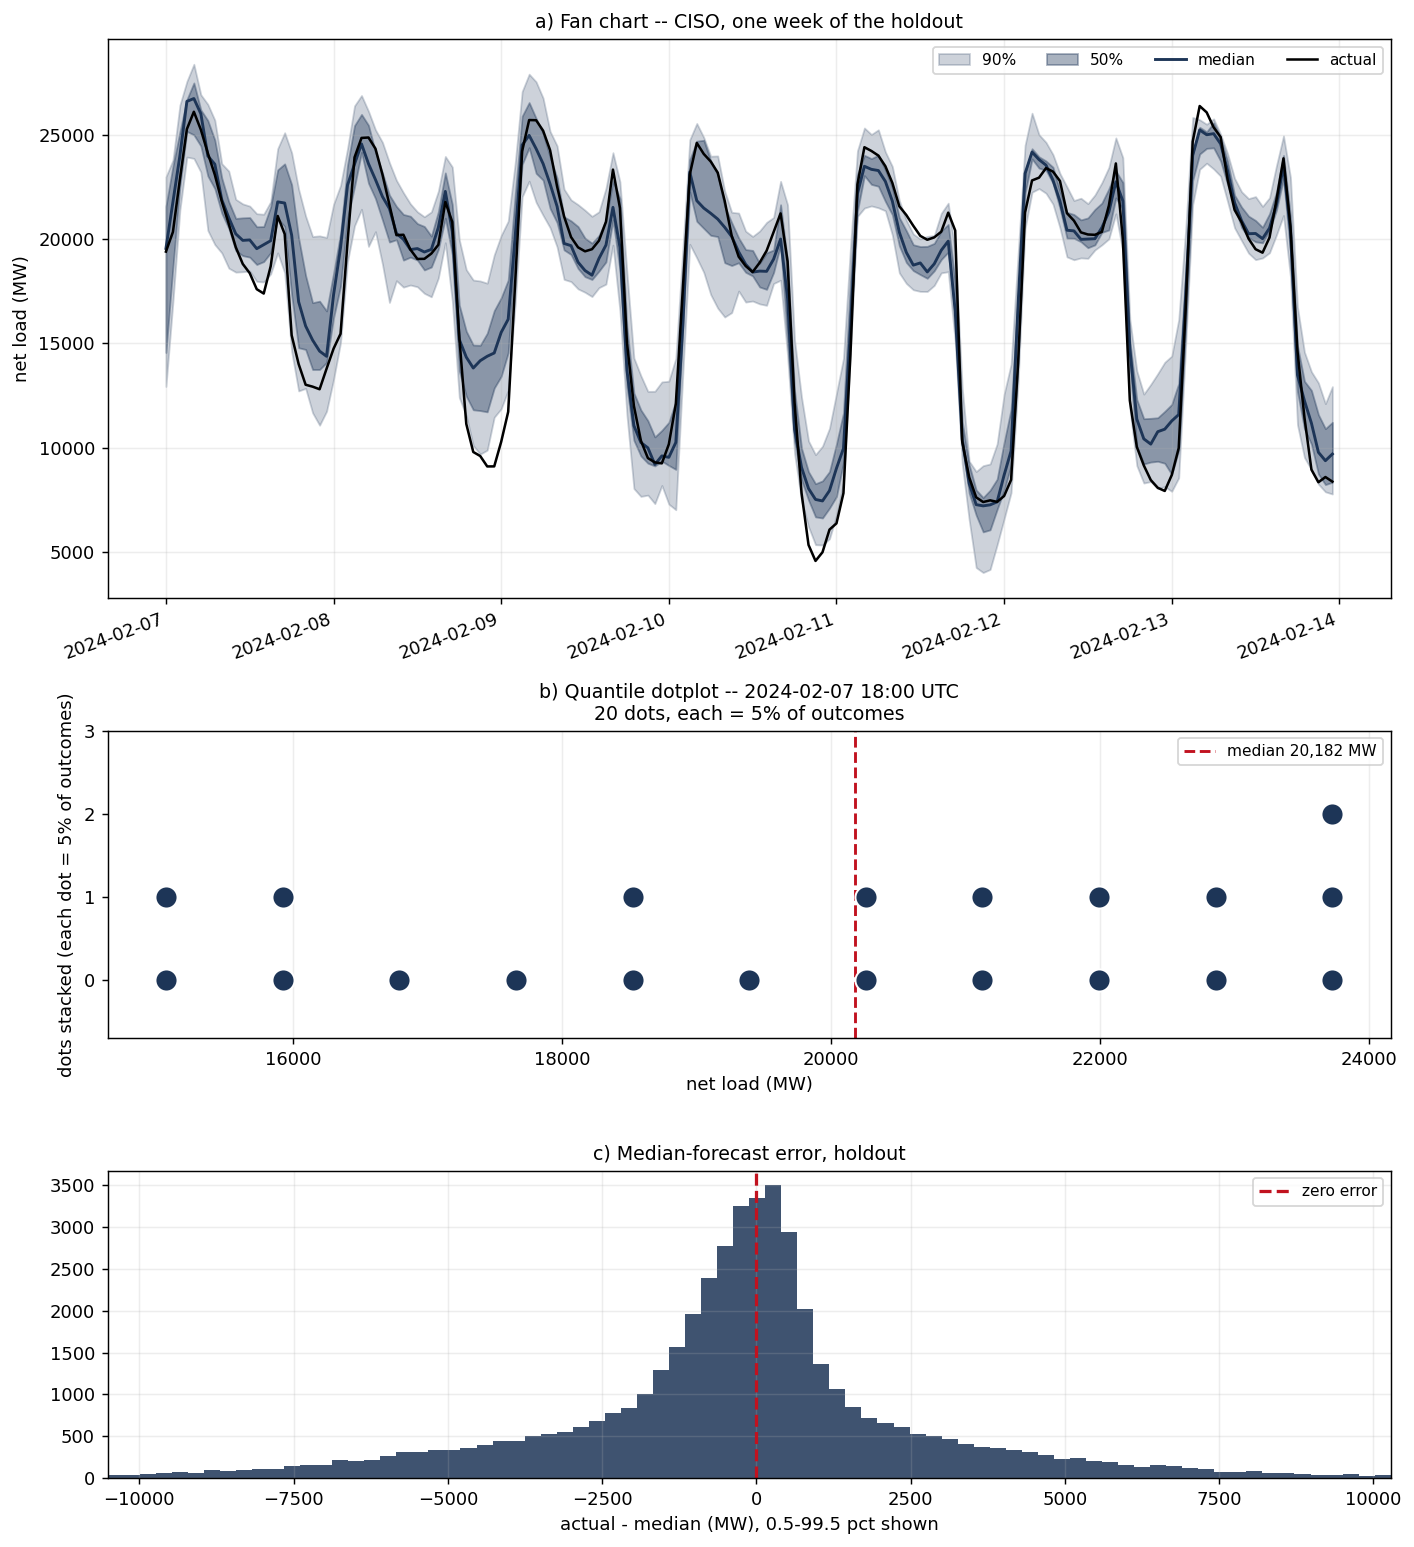

In [8]:
# WHAT: the same forecast in three encodings, on one week of one zone.
# WHY:  the encoding decides what a reader can actually do with the interval. A fan
#       chart shows the shape of the uncertainty; a quantile dotplot supports
#       COUNTING, which is what someone making a yes/no reserve call does; a bare
#       density invites comparing peak heights when the decision depends on areas.
z = cfg.ZONES[0]
m = (hold[cfg.GROUP_COL].to_numpy() == z)
sl = slice(0, 24 * 7)
t = hold[cfg.TIME_COL].to_numpy()[m][sl]

# Three rows. As a 1x3 strip the dotplot and histogram were each a third of the
# width the report allows, and their titles collided.
fig = plt.figure(figsize=(11.0, 12.0))
gs = fig.add_gridspec(3, 1, height_ratios=[2.0, 1.1, 1.1])

ax = fig.add_subplot(gs[0, 0])
ax.fill_between(t, Q[0.05].to_numpy()[m][sl], Q[0.95].to_numpy()[m][sl],
                alpha=0.22, color="#1d3557", label="90%")
ax.fill_between(t, Q[0.25].to_numpy()[m][sl], Q[0.75].to_numpy()[m][sl],
                alpha=0.38, color="#1d3557", label="50%")
ax.plot(t, Q[0.5].to_numpy()[m][sl], lw=1.6, color="#1d3557", label="median")
ax.plot(t, yh[m][sl], lw=1.4, color="black", label="actual")
ax.set_title(f"a) Fan chart -- {z}, one week of the holdout", fontsize=10.5)
ax.set_ylabel("net load (MW)"); ax.legend(fontsize=8.5, ncol=4); ax.grid(alpha=0.22)
for lab in ax.get_xticklabels():
    lab.set_rotation(20); lab.set_ha("right")

# One hour, as 20 dots: each dot is a 5% chance. Counting dots below a threshold
# IS the reserve question, and it needs no distributional literacy to read.
hour_i = 18
row = np.array([Q[q].to_numpy()[m][sl][hour_i] for q in QS])
dots = np.interp(np.linspace(0.025, 0.975, 20), QS, row)
# STACK THE DOTS ON THE VALUE AXIS so the panel can actually be counted. Binned
# into 11 columns and stacked within each bin -- a Wilkinson dotplot -- so the
# height of a column IS the number of the twenty outcomes landing near that value.
_o = np.sort(dots)
_edges = np.linspace(_o[0], _o[-1], 12)
_idx = np.clip(np.digitize(_o, _edges) - 1, 0, len(_edges) - 2)
_stack = np.array([int((_idx[:k] == _idx[k]).sum()) for k in range(len(_o))])
_xs = (_edges[_idx] + _edges[_idx + 1]) / 2
ax = fig.add_subplot(gs[1, 0])
ax.scatter(_xs, _stack, s=150, color="#1d3557", edgecolor="white",
           linewidth=1.1, zorder=3)
ax.axvline(float(np.median(_o)), color="#c1121f", ls="--", lw=1.6,
           label=f"median {np.median(_o):,.0f} MW")
ax.set_xlabel("net load (MW)")
ax.set_ylabel("dots stacked (each dot = 5% of outcomes)")
ax.set_ylim(-0.7, max(3, int(_stack.max()) + 1))
ax.set_yticks(range(0, int(_stack.max()) + 2))
ax.legend(fontsize=8.5); ax.grid(alpha=0.22, axis="x")
ax.set_title(f"b) Quantile dotplot -- {pd.Timestamp(t[hour_i]):%Y-%m-%d %H:%M} UTC"
             f"\n20 dots, each = 5% of outcomes", fontsize=10.5)

ax = fig.add_subplot(gs[2, 0])
err = yh - Q[0.5].to_numpy()
# CLIP THE VIEW, AND SAY SO ON THE AXIS. Drawn to the full data range the panel
# ran to +60,000 MW with all the mass inside +/-15,000, so the distribution was a
# spike in the left third of an otherwise empty box.
_lo, _hi = (float(v) for v in np.percentile(err, [0.5, 99.5]))
ax.hist(err, bins=80, range=(_lo, _hi), color="#1d3557", alpha=0.85)
ax.axvline(0, color="#c1121f", ls="--", lw=1.8, label="zero error")
ax.set_xlim(_lo, _hi)
ax.legend(fontsize=8.5)
ax.set_title("c) Median-forecast error, holdout", fontsize=10.5)
ax.set_xlabel("actual - median (MW), 0.5-99.5 pct shown"); ax.grid(alpha=0.22)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "06_fan_chart.png", bbox_inches="tight")
plt.show()


**Figure: `06_fan_chart.png`**

**What this shows:** (a) Fan chart with the raw 50% and 90% bands for CISO, 2024-02-07 to 02-14; (b) a quantile dotplot for one hour; (c) the median-forecast error over the whole holdout.

**What I see:** In this week the actual leaves the 90% band several times, mostly at the daily minima. The dotplot's median is 20,182 MW. The histogram is sharply peaked near zero; over-forecasts are the more frequent miss, while the rare extreme misses are under-forecasts.

**What it means:** On this week the under-coverage sits in the solar-driven troughs. This is a visual reading of one week of one zone, not a measurement.

**What I do:** Use the dotplot in the executive summary and the fan chart in the operational section, always with the achieved coverage beside it (88.7%, and 84.7% on duck evenings).

### 6.4b — Overlapping confidence intervals and the paired test

Three comparisons scored on the same holdout rows. For each: the 90% CI of each method's mean, whether they overlap, and a paired test on the difference. Because a hard hour is hard for both methods, the difference has much less variance than either mean. The test runs on zone × date block means (about 1,970 units), since hourly rows are autocorrelated; Wilcoxon is reported beside the t-test.

--- each mean's 90% CI, whether they overlap, and the paired test on block means ---


,mean_a,mean_b,cis_overlap,mean_diff,n_units,paired_t,paired_p,wilcoxon_p,diff_excludes_zero
pinball at the median: raw vs rearranged,1078.602132,1075.82679,True,2.775342,1974,5.213242,0.0,0.0,True
|error| of the median: pooled shift vs Mondrian shift,2197.284425,2180.33988,True,16.944545,1974,3.66319,0.000256,0.163809,True
Winkler per row: pooled CQR vs Mondrian CQR,12198.948054,11617.11632,True,581.831733,1974,10.636028,0.0,0.0,True



comparisons where the CIs overlap AND the paired test rejects at 5%: ['pinball at the median: raw vs rearranged', '|error| of the median: pooled shift vs Mondrian shift', 'Winkler per row: pooled CQR vs Mondrian CQR']


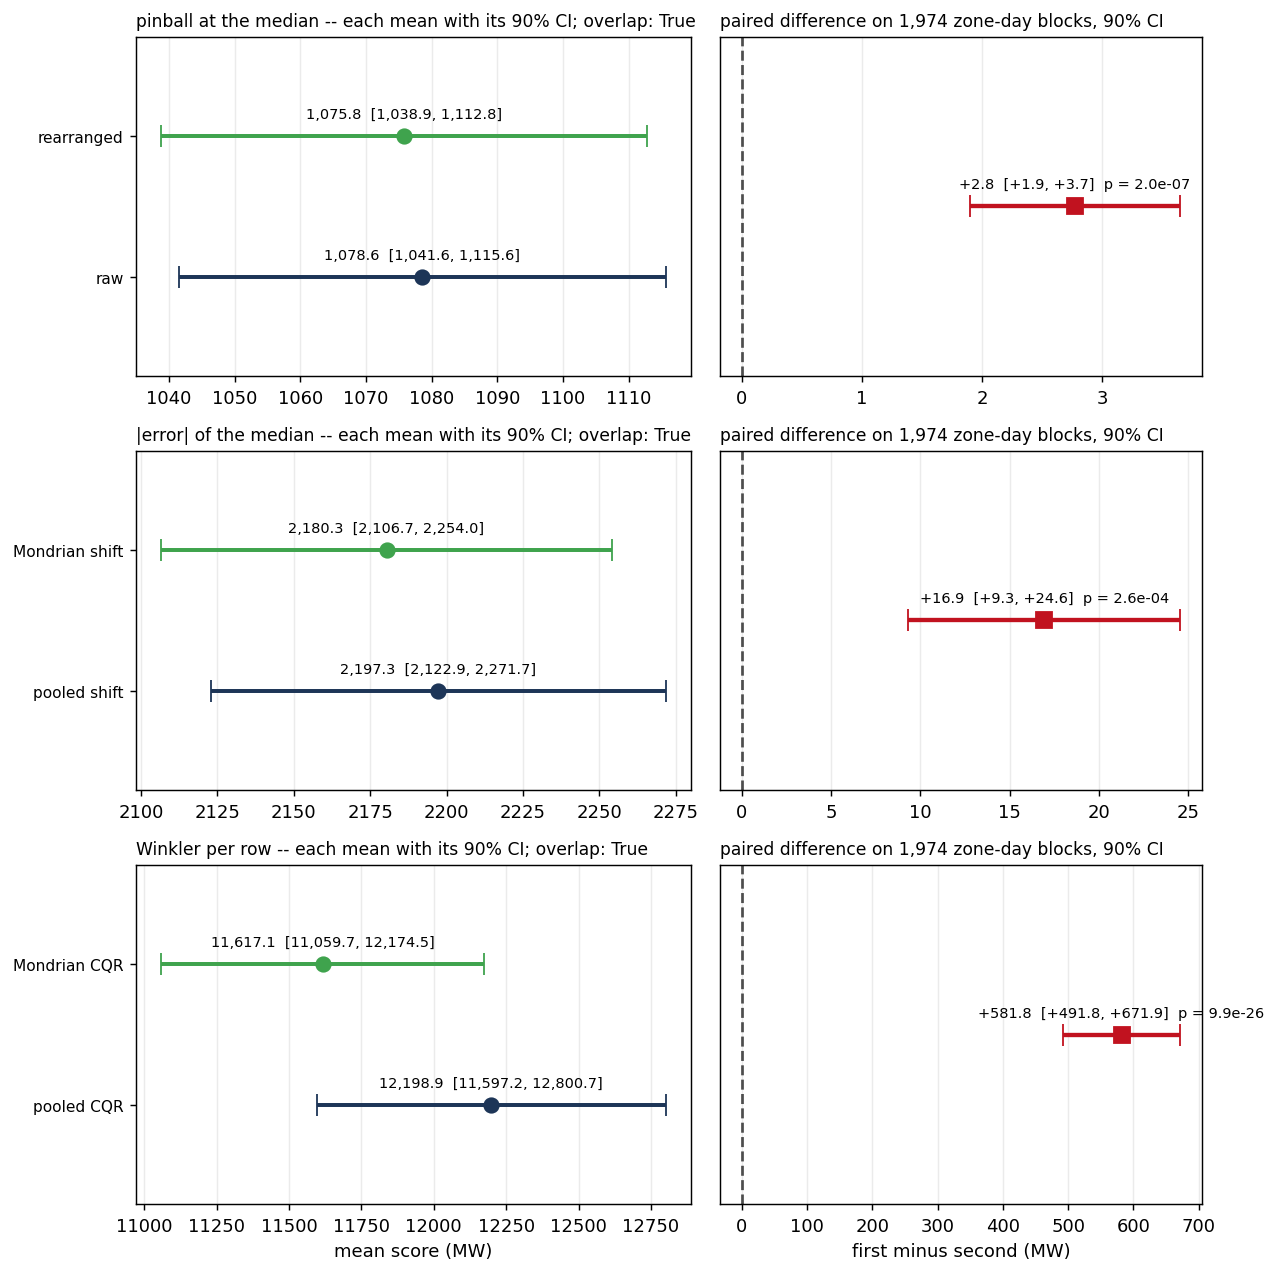

In [9]:
# WHAT: three paired comparisons -- overlapping CIs beside a decisive paired test.
# WHY:  item 4 of the without-notes block. The CI of a mean and the CI of a paired
#       difference answer different questions, and only the second one is the
#       model-comparison question.
# HONESTY ABOUT n: the paired test runs on zone x date block means, not on rows.
blocks = (hold[cfg.GROUP_COL].astype(str) + "_"
          + hold[cfg.TIME_COL].dt.strftime("%Y-%m-%d")).to_numpy()


def _pin_rows(pred, q):
    e = yh - np.asarray(pred, dtype=float)
    return np.maximum(q * e, (q - 1) * e)


def _wk_rows(lo, hi):
    lo, hi = np.asarray(lo, dtype=float), np.asarray(hi, dtype=float)
    pen = np.where(yh < lo, 2 / ALPHA * (lo - yh), np.where(yh > hi, 2 / ALPHA * (yh - hi), 0.0))
    return (hi - lo) + pen


pairs = {
    "pinball at the median: raw vs rearranged":
        (_pin_rows(Q_raw[0.5], 0.5), _pin_rows(Q[0.5], 0.5)),
    "|error| of the median: pooled shift vs Mondrian shift":
        (np.abs(yh - Q_cal_levels[0.5].to_numpy()), np.abs(yh - Q_mond_levels[0.5].to_numpy())),
    "Winkler per row: pooled CQR vs Mondrian CQR":
        (_wk_rows(cqr_lo, cqr_hi), _wk_rows(mcqr_lo, mcqr_hi)),
}
ov_rows = {}
for name, (a, b) in pairs.items():
    ov_rows[name] = U.overlap_vs_paired(a, b, blocks=blocks, level=0.90)
ov_tbl = pd.DataFrame(ov_rows).T[["mean_a", "mean_b", "cis_overlap", "mean_diff",
                                  "n_units", "paired_t", "paired_p", "wilcoxon_p",
                                  "diff_excludes_zero"]]
print("--- each mean's 90% CI, whether they overlap, and the paired test on block means ---")
display(ov_tbl)
the_case = [n for n, r in ov_rows.items() if r["cis_overlap"] and r["paired_p"] < 0.05]
print(f"\ncomparisons where the CIs overlap AND the paired test rejects at 5%: "
      f"{the_case if the_case else 'none'}")

fig, axes = plt.subplots(len(pairs), 2, figsize=(10.0, 3.3 * len(pairs)),
                         gridspec_kw={"width_ratios": [1.15, 1]})
for i, (name, r) in enumerate(ov_rows.items()):
    ax = axes[i, 0]
    for j, (lab, m, ci) in enumerate([("first", r["mean_a"], r["ci_a"]),
                                      ("second", r["mean_b"], r["ci_b"])]):
        ax.errorbar([m], [j], xerr=[[m - ci[0]], [ci[1] - m]], fmt="o", ms=8, capsize=6,
                    lw=2.2, color="#1d3557" if j == 0 else "#3fa34d")
        ax.annotate(f"{m:,.1f}  [{ci[0]:,.1f}, {ci[1]:,.1f}]", (m, j), xytext=(0, 10),
                    textcoords="offset points", ha="center", fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(name.split(": ")[1].split(" vs "), fontsize=8.5)
    ax.set_ylim(-0.7, 1.7)
    ax.set_title(f"{name.split(': ')[0]} -- each mean with its 90% CI; "
                 f"overlap: {r['cis_overlap']}", fontsize=9.5, loc="left")
    ax.grid(alpha=0.25, axis="x")
    ax = axes[i, 1]
    d, cd = r["mean_diff"], r["ci_diff"]
    ax.errorbar([d], [0], xerr=[[d - cd[0]], [cd[1] - d]], fmt="s", ms=9, capsize=6, lw=2.4,
                color="#c1121f" if r["diff_excludes_zero"] else "0.5")
    ax.axvline(0, ls="--", color="0.3", lw=1.5)
    ax.annotate(f"{d:+,.1f}  [{cd[0]:+,.1f}, {cd[1]:+,.1f}]  p = {r['paired_p']:.1e}",
                (d, 0), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8)
    ax.set_yticks([]); ax.set_ylim(-0.7, 0.7)
    ax.set_title(f"paired difference on {r['n_units']:,} zone-day blocks, 90% CI",
                 fontsize=9.5, loc="left")
    ax.grid(alpha=0.25, axis="x")
axes[-1, 0].set_xlabel("mean score (MW)"); axes[-1, 1].set_xlabel("first minus second (MW)")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "06_overlap_vs_paired.png", bbox_inches="tight")
plt.show()

R.save("nb06", {"overlap_vs_paired": {
    n: {k: (list(map(float, v)) if isinstance(v, tuple) else
            (bool(v) if isinstance(v, (bool, np.bool_)) else
             (int(v) if isinstance(v, (int, np.integer)) else float(v))))
        for k, v in r.items()} for n, r in ov_rows.items()},
    "overlap_vs_paired_cases": the_case,
    "overlap_vs_paired_blocks": "zone x date means",
});


**Figure: `06_overlap_vs_paired.png`**

**What I see:** Pinball at the median, raw vs rearranged: 1,078.6 vs 1,075.8, intervals almost identical, paired difference +2.8 MW [+1.9, +3.7], p = 2.0 × 10⁻⁷. Absolute error, pooled vs Mondrian median: difference +16.9 MW, t-test p = 2.6 × 10⁻⁴ but Wilcoxon 0.164. Winkler, pooled vs Mondrian CQR: 12,198.9 vs 11,617.1, difference +581.8 MW, p = 9.9 × 10⁻²⁶.

**What it means:** In all three rows the CIs overlap and the paired test still rejects. Overlapping intervals do not mean no significant difference. In row 2 the gain comes from a minority of zone-days, so the rank test does not pick it up.

**What I do:** State every model comparison as a paired difference with its own interval, on zone-day blocks, and quote both tests when the difference is skewed.

### 6.5 — Policy: which encoding for which reader

- **Model comparison:** the coverage bars and width-vs-Winkler panels of `06_calibration.png`, and paired differences with their own intervals (`06_overlap_vs_paired.png`).
- **The forecast itself (operators):** the fan chart, always with the achieved coverage printed: 88.7% overall, or the zone's own figure (86.7% in CISO, 91.7% in BPAT).
- **Executive summary:** the quantile dotplot, with one sentence saying it is a prediction interval, 59 times wider than the confidence interval on zone-day blocks, and that reserve is sized from it.

The error histogram stays in the technical appendix. A confidence interval is never shown in an operational context, and every coverage figure quoted is the achieved one.

In [10]:
# WHAT: persist the quantile matrix reserve is sized from.
# WHY:  downstream readers cannot refit seven quantile models, and — the part that changed
#       on 2026-08-23 — it must not size reserve off the UNCALIBRATED band. The
#       headline $1.13 bn was computed from uncalibrated intervals, measured then at
#       81.1% coverage against a nominal 90% with 8.5% of rows not monotone (80.4%
#       and 10.0% in this run). Both the raw
#       and the calibrated columns are written, so reserve can be re-priced on the
#       corrected distribution and still show what the old one gave.
# NOTE: columns are renamed to strings first. Parquet has no float column names, so
#       writing 0.05 and reading it back gives '0.05' — a KeyError downstream
#       that would look like a missing quantile rather than a dtype round-trip.

def _q_frame(frame, prefix=""):
    return frame.rename(columns=lambda q: f"{prefix}q{int(round(100 * float(q))):02d}")

hq = _q_frame(Q[QS])                          # raw, rearranged, full-dev fit
# cal_* and cqr_* are the SHIPPED band -- Mondrian by zone since 2026-09-09. The
# pooled columns that shipped before are kept under pooled_* so a reader can show
# what the change in calibration is worth in reserve.
hq = pd.concat([hq, _q_frame(Q_mond_levels, "cal_"),
                _q_frame(Q_cal_levels[[0.05, 0.5, 0.95]], "pooled_cal_")], axis=1)
hq["cqr_lo"], hq["cqr_hi"] = mcqr_lo, mcqr_hi
hq["cqr_scaled_lo"], hq["cqr_scaled_hi"] = mcqrs_lo, mcqrs_hi
hq["pooled_cqr_lo"], hq["pooled_cqr_hi"] = cqr_lo, cqr_hi
hq["conformal_lo"], hq["conformal_hi"] = conf_lo, conf_hi
hq[cfg.TIME_COL] = hold[cfg.TIME_COL].to_numpy()
hq[cfg.GROUP_COL] = hold[cfg.GROUP_COL].to_numpy()
hq["actual"] = yh          # yh is `y_hold`, already an ndarray since cell 2
hq.to_parquet(cfg.DATA_PROC / "holdout_quantiles.parquet", index=False)

OUT = cfg.DATA_PROC / "uncertainty"
OUT.mkdir(parents=True, exist_ok=True)
hq.to_parquet(OUT / "holdout_intervals.parquet", index=False)
wdf.to_parquet(OUT / "weather_widening_by_horizon.parquet", index=False)
pd.DataFrame({"level": LEVELS, "empirical_before": emp_before,
              "empirical_after": emp_after}).to_parquet(
    OUT / "calibration_curve.parquet", index=False)
cmp_tbl.reset_index().to_parquet(OUT / "interval_methods.parquet", index=False)
op.reset_index().to_parquet(OUT / "operational_weather_by_horizon.parquet", index=False)
(OUT / "manifest.json").write_text(json.dumps({
    "built_by": "notebook 06",
    "model": "notebook 04 per-horizon champion, quantile loss substituted",
    "champion_params": PARAMS,
    "panel_crc32": X.panel_hash(),
    "quantiles": QS,
    "levels": LEVELS,
    "primary_interval": PRIMARY,
    "calibration": {
        "alpha": ALPHA, "calibration_fraction": CAL_FRAC,
        "calibration_rows": int(len(sub_cal)),
        "split": "chronological — the last 20% of dev, never random",
        "cqr_margin_mw": float(m_add),
        "cqr_scaled_margin": float(m_scl),
        "mondrian_by": cfg.GROUP_COL,
        "mondrian_margins_mw": {str(z): float(m) for z, m in mm_add.items()},
        "mondrian_min_cell_rows": int(MIN_CELL),
        "split_conformal_half_width_mw": float(q_conf),
        "level_shifts_mw": {str(k): float(v) for k, v in shifts.items()},
    },
    "achieved_coverage_90": {n: float(cmp_tbl.loc[n, "coverage"]) for n in cmp_tbl.index},
    "weather": {
        "training_weather": "ERA5 reanalysis, 2019-2024",
        "scoring_weather": "archived forecast runs at the matching lead (section 6.3b)",
        "injected_noise_is_superseded": True,
    },
    "files": {
        "holdout_intervals.parquet": "per-row raw and calibrated quantiles, all bounds, actual; "
                                     "cal_*/cqr_* are Mondrian by zone, pooled_* the pooled arm",
        "weather_widening_by_horizon.parquet": "width and coverage at noise scale 0 and 1",
        "calibration_curve.parquet": "nominal vs empirical, before and after calibration",
        "interval_methods.parquet": "coverage, width and Winkler for all nine arms",
        "operational_weather_by_horizon.parquet": "MAE and p95 under reanalysis vs forecast",
    },
}, indent=2), encoding="utf-8")

R.save("nb06", {"holdout_quantiles_rows": int(len(hq))})
print(f"wrote {len(list(OUT.glob('*')))} files to {OUT}")
print("\nnotebook 06 complete")
print(f"  champion CV MAE          {BP['cv_mae']:,.1f} MW")
print(f"  crossings                {cross_rate:.3%} -> {cross_final:.3%} after rearrangement")
print(f"  nominal 90% coverage     raw {cmp_tbl.loc['raw quantile GBM (full dev)', 'coverage']:.1%}"
      f"  ->  {PRIMARY} {cov_primary:.1%}")
print(f"  median                   {med_before:.3f} -> {med_after:.3f}")
print(f"  Winkler                  raw {cmp_tbl.loc['raw quantile GBM (full dev)', 'winkler']:,.0f}"
      f"  ->  {PRIMARY} {cmp_tbl.loc[PRIMARY, 'winkler']:,.0f}")
print(f"  weather, MEASURED        " + ", ".join(
    f"h={int(h)}: {op.loc[h, 'penalty_mw']:+,.0f} MW" for h in op.index))


wrote 7 files to C:\Users\alanm\OneDrive\Área de Trabalho\MADS_Milestone2 review\data\processed\uncertainty

notebook 06 complete
  champion CV MAE          2,107.3 MW
  crossings                10.034% -> 0.000% after rearrangement
  nominal 90% coverage     raw 80.4%  ->  CQR additive, Mondrian by zone 88.7%
  median                   0.541 -> 0.538
  Winkler                  raw 12,125  ->  CQR additive, Mondrian by zone 11,545
  weather, MEASURED        h=1: +0 MW, h=24: -10 MW, h=48: +2 MW, h=72: +37 MW
